Try to do some analysis on the clusters by plot vs movie admissions in different countries


In [1]:
import ast
import json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
PROJECT_ROOT = Path.cwd().parents[0]  # one level up from Analysis/

DATA_PATH = PROJECT_ROOT / "Data" / "Lumiere_Country_Full_Backup.csv"

CLUSTERS_PATH = (
    PROJECT_ROOT / "outputs" / "text_clustering"
    / "results_content_only" / "clustered_films_k6.csv"
)

print("Project root:", PROJECT_ROOT)
print("Data path:", DATA_PATH, "| exists:", DATA_PATH.exists())
print("Clusters path:", CLUSTERS_PATH, "| exists:", CLUSTERS_PATH.exists())

Project root: c:\Users\juliu\Documents\GitHub\Analytics2Action
Data path: c:\Users\juliu\Documents\GitHub\Analytics2Action\Data\Lumiere_Country_Full_Backup.csv | exists: True
Clusters path: c:\Users\juliu\Documents\GitHub\Analytics2Action\outputs\text_clustering\results_content_only\clustered_films_k6.csv | exists: True


In [12]:
# Both files originate from the same source in the same order,
# so we align by row index rather than joining on a text column.
assert len(df_admissions) == len(df_clusters), "Row count mismatch!"

df = df_admissions.copy()
df["cluster"] = df_clusters["cluster"].values

print(f"Rows: {len(df)}")
print(f"\nCluster distribution:\n{df['cluster'].value_counts().sort_index()}")

# Sanity check: spot-check that rows actually correspond.
for i in [0, 100, 500, 999]:
    match = df.loc[i, "plotShort"] == df_clusters.loc[i, "plotShort"]
    print(f"Row {i} plotShort match: {match}")

Rows: 2000

Cluster distribution:
cluster
0    297
1    374
2    294
3    356
4    391
5    288
Name: count, dtype: int64
Row 0 plotShort match: True
Row 100 plotShort match: True
Row 500 plotShort match: True
Row 999 plotShort match: True


In [14]:
print(f"Production - non-null: {df['production'].notna().sum()} / {len(df)}")
print(f"\nSample values:")
for val in df["production"].dropna().head(5):
    print(f"  [{len(val)} chars] {val[:200]}...")

Production - non-null: 2000 / 2000

Sample values:
  [880 chars] Music Box Films, Solopan, Orange Entertainment, Music Box Films Home Entertainment, Arsenal Filmverleih, Caramel Films, Cinéart, Frenetic Films, good movies!, Memento Films, Midas Filmes, Mozinet, Par...
  [87 chars] Uncork'd Entertainment, Viva Pictures, Enderby Entertainment, Tony-Seven Films, Telepix...
  [1387 chars] Magnolia Pictures, Mares Filmes, BIM Distribuzione, D Productions, Discovery Film & Video Distribution, Festive Films, Film1, Group Power, HBO Max, Hollywood Classic Entertainment, Independenta Film, ...
  [343 chars] Columbia Pictures, Dear Film, Columbia Pictures Corporation, Columbia Film, Columbia-Bavaria Filmgesellschaft m.b.H., Kamera, As Films S.A., Columbia Films, Columbia Films, Columbia Films, Columbia In...
  [812 chars] Cineville, Westlake Entertainment Group, Paragon Pictures (II), Crest International, Picture Entertainment, Primer Plano Film Group, Cinemacguffin, Teleview International, Vend

In [15]:
KEEP_COLUMNS = [
    "titleId",
    "originalTitle",
    "releaseYear",
    "runtimeMinutes",
    "isAdult",
    "mainCountry",
    "firstLanguage",
    "genres",
    "keywords",
    "imdbRating",
    "numberOfVotes",
    "cluster",
    "country_admissions"
]

available = [c for c in KEEP_COLUMNS if c in df.columns]
missing = [c for c in KEEP_COLUMNS if c not in df.columns]
print(f"Keeping: {available}")
if missing:
    print(f"Not found (skipped): {missing}")

df = df[available].copy()
print(f"\nSlimmed shape: {df.shape}")

Keeping: ['titleId', 'originalTitle', 'releaseYear', 'runtimeMinutes', 'isAdult', 'mainCountry', 'firstLanguage', 'genres', 'keywords', 'imdbRating', 'numberOfVotes', 'cluster', 'country_admissions']

Slimmed shape: (2000, 13)


In [16]:
def parse_country_admissions(value):
    """Parse the country_admissions JSON string into a dict."""
    if pd.isna(value) or value == "Not Found":
        return {}
    try:
        return json.loads(value.replace('""', '"'))
    except (json.JSONDecodeError, TypeError):
        return {}

# Expand each film's admissions dict into rows.
records = []
for idx, row in df.iterrows():
    admissions = parse_country_admissions(row["country_admissions"])
    for country, count in admissions.items():
        if country.startswith("Total"):
            continue
        records.append({
            "titleId": row["titleId"],
            "originalTitle": row["originalTitle"],
            "releaseYear": row["releaseYear"],
            "runtimeMinutes": row["runtimeMinutes"],
            "isAdult": row["isAdult"],
            "mainCountry": row["mainCountry"],
            "firstLanguage": row["firstLanguage"],
            "genres": row["genres"],
            "keywords": row["keywords"],
            "imdbRating": row["imdbRating"],
            "cluster": row["cluster"],
            "country": country,
            "admissions": count
        })

df_long = pd.DataFrame(records)

print(f"Long format: {len(df_long)} rows")
print(f"Films represented: {df_long['titleId'].nunique()}")
print(f"Countries found: {df_long['country'].nunique()}")
print(f"\nCountry codes:\n{sorted(df_long['country'].unique())}")
print(f"\nSample:")
df_long.head(10)

Long format: 22976 rows
Films represented: 1840
Countries found: 40

Country codes:
['AL', 'AT', 'BA', 'BE', 'BG', 'CH', 'CY', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GB', 'GB_IE', 'GE', 'GR', 'HR', 'HU', 'IE', 'IS', 'IT', 'LI', 'LT', 'LU', 'LV', 'ME', 'MK', 'NL', 'NO', 'PL', 'PT', 'RO', 'RS', 'SE', 'SI', 'SK', 'TR', 'UA']

Sample:


,titleId,originalTitle,releaseYear,runtimeMinutes,isAdult,mainCountry,firstLanguage,genres,keywords,imdbRating,cluster,country,admissions
0,tt3042384,Ida,2013.0,82.0,False,PL,pl,Drama,"poland, 1960s, jew, novitiate, family secret, ...",7.4,4,AT,3063
1,tt3042384,Ida,2013.0,82.0,False,PL,pl,Drama,"poland, 1960s, jew, novitiate, family secret, ...",7.4,4,BE,27783
2,tt3042384,Ida,2013.0,82.0,False,PL,pl,Drama,"poland, 1960s, jew, novitiate, family secret, ...",7.4,4,CH,27774
3,tt3042384,Ida,2013.0,82.0,False,PL,pl,Drama,"poland, 1960s, jew, novitiate, family secret, ...",7.4,4,CY,64
4,tt3042384,Ida,2013.0,82.0,False,PL,pl,Drama,"poland, 1960s, jew, novitiate, family secret, ...",7.4,4,CZ,17410
5,tt3042384,Ida,2013.0,82.0,False,PL,pl,Drama,"poland, 1960s, jew, novitiate, family secret, ...",7.4,4,DE,33780
6,tt3042384,Ida,2013.0,82.0,False,PL,pl,Drama,"poland, 1960s, jew, novitiate, family secret, ...",7.4,4,DK,44405
7,tt3042384,Ida,2013.0,82.0,False,PL,pl,Drama,"poland, 1960s, jew, novitiate, family secret, ...",7.4,4,EE,2744
8,tt3042384,Ida,2013.0,82.0,False,PL,pl,Drama,"poland, 1960s, jew, novitiate, family secret, ...",7.4,4,ES,106892
9,tt3042384,Ida,2013.0,82.0,False,PL,pl,Drama,"poland, 1960s, jew, novitiate, family secret, ...",7.4,4,FI,31017


So now the format is movie, country addmissions. 

In [17]:
# Films per country and basic admissions stats.
country_stats = (
    df_long.groupby("country")
    .agg(
        n_films=("titleId", "nunique"),
        total_admissions=("admissions", "sum"),
        mean_admissions=("admissions", "mean"),
        median_admissions=("admissions", "median")
    )
    .sort_values("n_films", ascending=False)
)

print(f"{'Country':<8} {'Films':>6} {'Total Adm':>14} {'Mean Adm':>12} {'Median Adm':>12}")
print("-" * 56)
for country, row in country_stats.iterrows():
    print(f"{country:<8} {int(row['n_films']):>6} {int(row['total_admissions']):>14,} {int(row['mean_admissions']):>12,} {int(row['median_admissions']):>12,}")

print(f"\n\nGB vs GB_IE overlap check:")
gb_films = set(df_long[df_long["country"] == "GB"]["titleId"])
gbie_films = set(df_long[df_long["country"] == "GB_IE"]["titleId"])
ie_films = set(df_long[df_long["country"] == "IE"]["titleId"])
print(f"GB films: {len(gb_films)}")
print(f"GB_IE films: {len(gbie_films)}")
print(f"IE films: {len(ie_films)}")
print(f"Films in BOTH GB and GB_IE: {len(gb_films & gbie_films)}")
print(f"Films in BOTH IE and GB_IE: {len(ie_films & gbie_films)}")

Country   Films      Total Adm     Mean Adm   Median Adm
--------------------------------------------------------
FR         1222    748,212,680      612,285      133,655
ES         1202    446,247,431      371,254       75,384
CH         1026     64,126,488       62,501       15,457
IT          985    328,400,004      333,401      106,624
NL          945    110,893,655      117,347       33,104
DE          912    530,784,053      582,000      131,455
BE          875     78,348,538       89,541       25,649
PT          855     46,474,084       54,355       11,368
GB          817    211,198,878      258,505        2,152
GB_IE       784    615,448,913      785,011      121,435
PL          767    137,510,543      179,283       55,863
AT          735     54,387,021       73,995       21,296
NO          730     44,215,710       60,569       14,237
DK          728     55,722,420       76,541       19,921
SE          726     62,325,670       85,848       21,290
HU          701     43,399,273 

In [18]:
# 1. Handle GB / IE / GB_IE overlap.
#    When a film has GB_IE, the separate GB and IE entries are residuals.
#    Drop the individual GB and IE rows for films that also have GB_IE.
films_with_gbie = set(df_long[df_long["country"] == "GB_IE"]["titleId"])

mask_redundant = (
    df_long["country"].isin(["GB", "IE"]) &
    df_long["titleId"].isin(films_with_gbie)
)
print(f"Dropping {mask_redundant.sum()} redundant GB/IE rows (covered by GB_IE)")
df_long = df_long[~mask_redundant].copy()

# 2. Drop countries with too few films for reliable z-scores.
MIN_FILMS = 50
country_film_counts = df_long.groupby("country")["titleId"].nunique()
small_countries = country_film_counts[country_film_counts < MIN_FILMS].index.tolist()
print(f"\nDropping {len(small_countries)} countries with <{MIN_FILMS} films: {small_countries}")
df_long = df_long[~df_long["country"].isin(small_countries)].copy()

print(f"\nCleaned long format: {len(df_long)} rows")
print(f"Countries remaining: {df_long['country'].nunique()}")
print(f"Films represented: {df_long['titleId'].nunique()}")

Dropping 603 redundant GB/IE rows (covered by GB_IE)

Dropping 5 countries with <50 films: ['AL', 'GE', 'LI', 'RS', 'UA']

Cleaned long format: 22297 rows
Countries remaining: 35
Films represented: 1840


In [ ]:
# Compute z-scores within each country.
df_long["admissions_zscore"] = (
    df_long.groupby("country")["admissions"]
    .transform(lambda x: (x - x.mean()) / x.std())
)

# Quick sanity check.
zscore_check = (
    df_long.groupby("country")["admissions_zscore"]
    .agg(["mean", "std", "min", "max", "count"])
    .round(3)
)
print("Z-score sanity check (mean should be ~0, std should be ~1):")
print(zscore_check.head(10))

# Look at the distribution — admissions are heavily right-skewed,
# so z-scores will be too.
print(f"\nOverall z-score distribution:")
print(df_long["admissions_zscore"].describe().round(3))

Z-score distribution (after log transform):
count    22297.000
mean        -0.000
std          0.999
min         -4.848
25%         -0.577
50%          0.124
75%          0.708
max          2.745
Name: admissions_zscore, dtype: float64


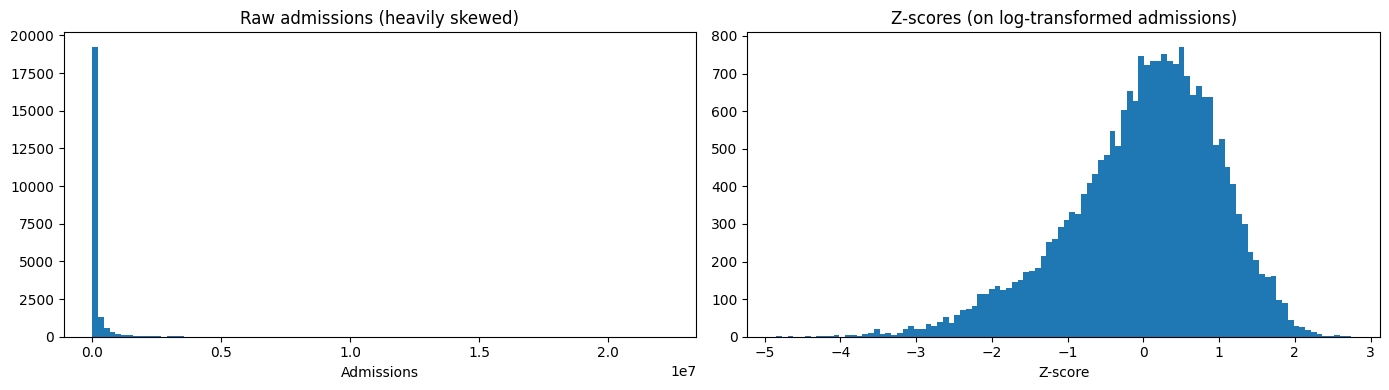

In [21]:
# Log-transform admissions before z-scoring.
# Using log1p (log(1+x)) to handle any zero values safely.
df_long["log_admissions"] = np.log1p(df_long["admissions"])

# Recompute z-scores on the log-transformed values.
df_long["admissions_zscore"] = (
    df_long.groupby("country")["log_admissions"]
    .transform(lambda x: (x - x.mean()) / x.std())
)

print("Z-score distribution (after log transform):")
print(df_long["admissions_zscore"].describe().round(3))

# Visual check.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df_long["admissions"], bins=100, edgecolor="none")
axes[0].set_title("Raw admissions (heavily skewed)")
axes[0].set_xlabel("Admissions")

axes[1].hist(df_long["admissions_zscore"], bins=100, edgecolor="none")
axes[1].set_title("Z-scores (on log-transformed admissions)")
axes[1].set_xlabel("Z-score")

plt.tight_layout()
plt.show()

In [22]:
# Add percentile rank per country (0-100 scale).
df_long["admissions_percentile"] = (
    df_long.groupby("country")["admissions"]
    .transform(lambda x: x.rank(pct=True) * 100)
)

print("Percentile distribution:")
print(df_long["admissions_percentile"].describe().round(1))

# Compare all three for a single film.
example = df_long[df_long["originalTitle"] == df_long["originalTitle"].iloc[0]]
print(f"\nExample: {example['originalTitle'].iloc[0]}")
print(example[["country", "admissions", "admissions_zscore", "admissions_percentile"]].head(10).to_string(index=False))

Percentile distribution:
count    22297.0
mean        50.1
std         28.9
min          0.1
25%         25.1
50%         50.1
75%         75.1
max        100.0
Name: admissions_percentile, dtype: float64

Example: Ida
country  admissions  admissions_zscore  admissions_percentile
     AT        3063          -0.980048              14.965986
     BE       27783           0.120957              52.114286
     CH       27774           0.476655              60.428850
     CY          64          -2.317847               1.574803
     CZ       17410          -0.047002              46.096096
     DE       33780          -0.534938              27.412281
     DK       44405           0.487977              66.620879
     EE        2744          -0.459221              31.389365
     ES      106892           0.357229              55.324459
     FI       31017           0.489986              69.413629


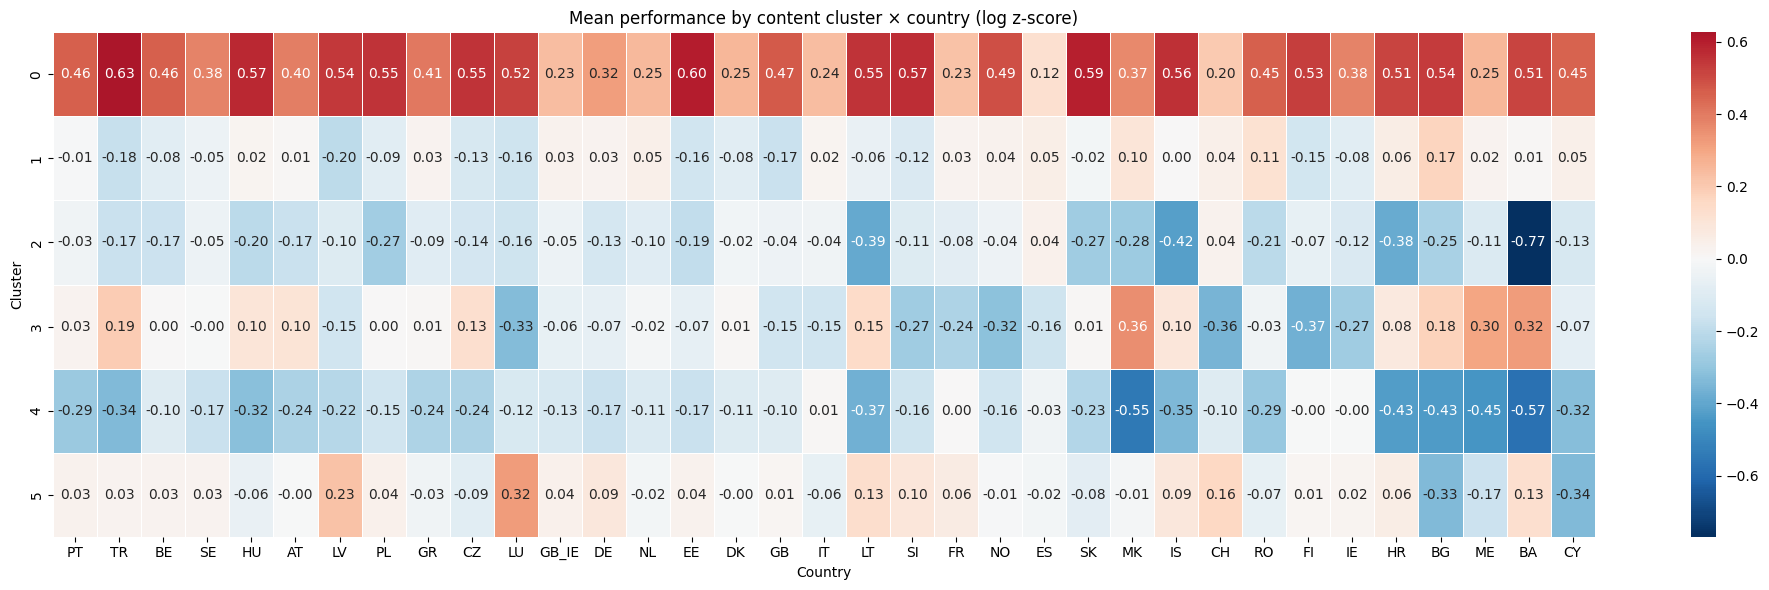


Interpretation: positive (red) = cluster over-performs in that country
               negative (blue) = cluster under-performs in that country


In [23]:
# Mean log z-score per cluster × country.
heatmap_data = (
    df_long.groupby(["cluster", "country"])["admissions_zscore"]
    .mean()
    .unstack(fill_value=0)
)

# Sort countries by total mean for readability.
country_order = heatmap_data.mean(axis=0).sort_values(ascending=False).index
heatmap_data = heatmap_data[country_order]

fig, ax = plt.subplots(figsize=(20, 6))
sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    ax=ax
)
ax.set_title("Mean performance by content cluster × country (log z-score)")
ax.set_xlabel("Country")
ax.set_ylabel("Cluster")

plt.tight_layout()
plt.show()

print("\nInterpretation: positive (red) = cluster over-performs in that country")
print("               negative (blue) = cluster under-performs in that country")


Here's what the heatmap reveals when you overlay the cluster profiles:

**Cluster 0 (Horror / Thriller / Supernatural)** — the clear winner across almost every market. This is your "universal blockbuster" cluster: horror, mystery, sci-fi with terms like "blood", "mysterious", "night". It over-performs everywhere, with the strongest pull in Turkey (+0.63), Luxembourg (+0.60), Hungary (+0.57), and the Balkans. This likely reflects that genre horror translates well across cultures — you don't need cultural context to be scared.

**Cluster 1 (Serious drama / War / Historical biography)** — nearly flat across the board, hovering around zero with slight negative leanings. These are prestige films ("based on true story", war, biography). They don't particularly over- or under-perform anywhere, suggesting this is a "steady baseline" category — respected but not a crowd-puller in any specific market.

**Cluster 2 (Buddy comedy / Coming-of-age / Friendship)** — the weakest performer overall, negative almost everywhere. Particularly poor in Iceland (-0.42), Bosnia (-0.77), and the Baltics. These are comedies about friends, school, and small-town life. The humor is likely culturally specific (British lad-comedy style, given the representative films like The Inbetweeners), which doesn't travel well.

**Cluster 3 (Crime thriller / Detective / Police procedural)** — mixed performance with an interesting pattern. Does well in Turkey (+0.19), Iceland (+0.36), and the Balkans (+0.30/+0.32), but poorly in the Baltics, Romania, and Ireland. These are darker, plot-driven thrillers (Hannibal, Man on Fire). The geographic split could reflect different appetites for violent crime narratives.

**Cluster 4 (Romance / Relationship drama / Literary adaptation)** — the weakest cluster, negative across nearly every country. Especially poor in Iceland (-0.55), Bosnia (-0.57), and the Balkans. These are intimate, character-driven films about relationships and marriage. They're likely niche even in their home markets, and the small-scale personal stories don't generate mass-market appeal anywhere.

**Cluster 5 (Adventure / Fantasy / Family)** — mostly neutral with one interesting spike: Luxembourg (+0.32). Otherwise close to zero everywhere. These are family-friendly adventure films (Golden Compass, Fantastic Beasts). They perform consistently but don't dominate any particular market.

**The big takeaway for your predictor:** content type matters far less than you might expect for most clusters — the variation across countries within a cluster is small (±0.3 z-scores). Cluster 0 (horror/thriller) is the exception, with a consistent positive effect everywhere. This suggests the predictor's power will come more from the interaction between content features and specific markets than from clusters alone. The keyword-level analysis might reveal sharper differences — want to move there next, or explore the country clustering first?

Country profiles shape: (35, 6)
(each row is a country, each column is its mean z-score for that content cluster)



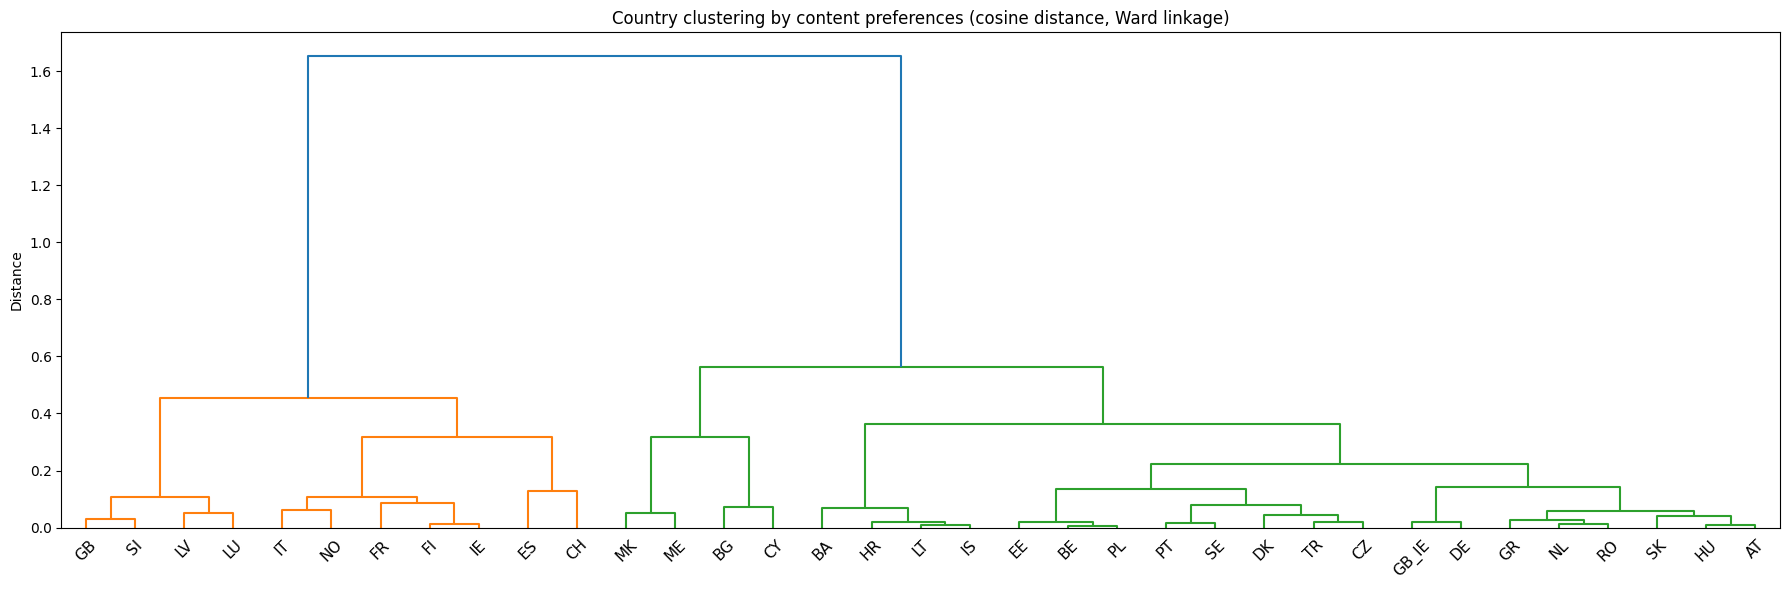

In [24]:
# Countries as rows, clusters as columns — each country's "taste profile".
country_profiles = heatmap_data.T

print(f"Country profiles shape: {country_profiles.shape}")
print("(each row is a country, each column is its mean z-score for that content cluster)\n")

# Hierarchical clustering with dendrogram — better than k-means here
# because we don't know how many groups exist and want to see the tree.
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist

distances = pdist(country_profiles.values, metric="cosine")
Z = linkage(distances, method="ward")

fig, ax = plt.subplots(figsize=(18, 6))
dendrogram(
    Z,
    labels=country_profiles.index.tolist(),
    leaf_font_size=11,
    ax=ax
)
ax.set_title("Country clustering by content preferences (cosine distance, Ward linkage)")
ax.set_ylabel("Distance")
plt.tight_layout()
plt.show()

Interesting tree. A few things stand out:

**The big split** at distance ~1.65 creates two major groups. This is the most fundamental divide in European content preferences.

**Left branch (orange)** — GB, SI, LV, LU, IT, NO, FR, FI, IE, ES, CH. This is a geographically mixed group, which is notable in itself. What these countries likely share is a *flatter* preference profile — looking back at the heatmap, these tend to be markets where the difference between clusters is relatively small. They're less extreme in their likes and dislikes. Within this branch you see some intuitive pairings: France-Finland-Ireland-Norway form a sub-cluster, and Spain-Switzerland are close.

**Right branch (green)** has two sub-groups:

The **Balkan/small market cluster** — MK, ME, BG, CY, BA, HR, LT, IS, EE. These are smaller markets that tend to show more extreme preferences — stronger positive response to cluster 0 (horror/thriller) and stronger negative response to clusters 2 and 4. Smaller markets may be more selective in what gets distributed there, which amplifies the signal.

The **Central/Northern European mainstream** — BE, PL, PT, SE, DK, TR, CZ, GB_IE, DE, GR, NL, RO, SK, HU, AT. This is the largest group and contains most of the major markets. Very tight pairings here: BE-PL, GB_IE-DE, SK-HU, NL-RO, PT-SE. Some of these make intuitive sense (SK-HU share a cultural border), while others are surprising (NL-RO, PT-SE) and suggest the content preferences are picking up on something beyond simple geography.

**Key takeaway:** content preferences don't map cleanly onto the geographic/linguistic blocs you might expect. The fact that Portugal clusters with Sweden, or Netherlands with Romania, rather than with their linguistic neighbours, means your predictor can't just use "region" as a proxy — it genuinely needs country-level modelling. This validates the whole approach.

Want to cut the tree into groups and visualize them on the heatmap to see the patterns more crisply?

Keyword analysis

In [25]:
# Parse keywords from the long dataframe.
def parse_keywords(value):
    if pd.isna(value) or value == "":
        return []
    try:
        items = [k.strip().lower() for k in str(value).split(",")]
        return [k for k in items if k]
    except:
        return []

# How many keywords per film?
keyword_counts = df_long.drop_duplicates("titleId")["keywords"].apply(parse_keywords).apply(len)

print(f"Keywords per film — mean: {keyword_counts.mean():.1f}, median: {keyword_counts.median():.0f}")
print(f"Films with zero keywords: {(keyword_counts == 0).sum()}")

# How many unique keywords total?
all_keywords = []
for kw_list in df_long.drop_duplicates("titleId")["keywords"].apply(parse_keywords):
    all_keywords.extend(kw_list)

keyword_freq = pd.Series(all_keywords).value_counts()
print(f"\nTotal unique keywords: {len(keyword_freq)}")
print(f"Keywords appearing 10+ times: {(keyword_freq >= 10).sum()}")
print(f"Keywords appearing 30+ times: {(keyword_freq >= 30).sum()}")
print(f"\nTop 20 keywords:")
print(keyword_freq.head(20))

Keywords per film — mean: 137.6, median: 101
Films with zero keywords: 0

Total unique keywords: 54607
Keywords appearing 10+ times: 4443
Keywords appearing 30+ times: 1365

Top 20 keywords:
murder                          639
death                           580
female nudity                   552
blood                           524
husband wife relationship       510
violence                        471
flashback                       450
cigarette smoking               417
kiss                            408
based on novel                  381
father son relationship         366
title spoken by character       362
independent film                356
father daughter relationship    356
dog                             346
mother son relationship         343
friendship                      336
photograph                      333
female rear nudity              323
male nudity                     310
Name: count, dtype: int64


In [26]:
# Explode keywords into the long format — one row per film × country × keyword.
MIN_KEYWORD_FREQ = 50

df_long["keywords_list"] = df_long["keywords"].apply(parse_keywords)

# Get keywords that appear in at least MIN_KEYWORD_FREQ films.
keyword_film_counts = (
    df_long.drop_duplicates("titleId")
    .explode("keywords_list")
    ["keywords_list"].value_counts()
)
valid_keywords = set(keyword_film_counts[keyword_film_counts >= MIN_KEYWORD_FREQ].index)
print(f"Keywords with {MIN_KEYWORD_FREQ}+ films: {len(valid_keywords)}")

# Explode and filter.
df_kw = df_long.explode("keywords_list")
df_kw = df_kw[df_kw["keywords_list"].isin(valid_keywords)].copy()
df_kw = df_kw.rename(columns={"keywords_list": "keyword"})

print(f"Exploded rows: {len(df_kw)}")

# Mean z-score per keyword × country.
kw_country = (
    df_kw.groupby(["keyword", "country"])["admissions_zscore"]
    .agg(["mean", "count"])
    .reset_index()
)

# Only keep keyword-country pairs with enough observations.
MIN_OBS = 10
kw_country = kw_country[kw_country["count"] >= MIN_OBS].copy()

print(f"Keyword × country pairs (min {MIN_OBS} obs): {len(kw_country)}")

Keywords with 50+ films: 723
Exploded rows: 1220870
Keyword × country pairs (min 10 obs): 24255


In [27]:
# For each keyword, compute the spread of mean z-scores across countries.
# High spread = countries disagree about this keyword = useful for predictor.
kw_variance = (
    kw_country.groupby("keyword")["mean"]
    .agg(["std", "min", "max", "count"])
    .rename(columns={"count": "n_countries"})
)
kw_variance["range"] = kw_variance["max"] - kw_variance["min"]

# Only keep keywords that appear in enough countries.
kw_variance = kw_variance[kw_variance["n_countries"] >= 15].copy()
kw_variance = kw_variance.sort_values("std", ascending=False)

print(f"Keywords with 15+ countries: {len(kw_variance)}")
print(f"\nTop 20 most divisive keywords (highest cross-country variance):")
print(kw_variance.head(20)[["std", "range", "min", "max", "n_countries"]].round(3).to_string())

print(f"\n\nTop 20 most universal keywords (lowest cross-country variance):")
print(kw_variance.tail(20)[["std", "range", "min", "max", "n_countries"]].round(3).to_string())

Keywords with 15+ countries: 722

Top 20 most divisive keywords (highest cross-country variance):
                      std  range    min    max  n_countries
keyword                                                    
blockbuster         0.426  1.728 -0.260  1.468           32
trust               0.311  1.290 -0.880  0.409           34
laughter            0.298  1.368 -1.308  0.060           33
live action         0.294  1.602 -0.715  0.887           30
villain             0.292  1.077 -0.239  0.838           34
crucifix            0.292  1.383 -1.161  0.222           27
rainstorm           0.288  1.061 -0.543  0.518           31
gas station         0.282  1.454 -1.219  0.235           32
countryside         0.279  0.965 -0.592  0.373           30
man                 0.279  1.600 -1.146  0.454           31
lust                0.279  1.515 -1.435  0.080           28
hero                0.274  1.011  0.005  1.016           32
underwear           0.266  1.203 -0.976  0.226           29
ri

The divisive keywords tell a clear story. "Blockbuster" is the most polarizing — some countries massively over-index on big commercial films (max z-score +1.47) while others are relatively indifferent. "Live action", "villain", "hero", "damsel in distress" all point to the same thing: big-budget genre entertainment divides European audiences. "British" is also divisive, which makes sense — British cultural specificity travels to some markets but not others. "Laughter", "lust", "crucifix" suggest that humor, sexuality, and religious themes land very differently across cultures.
The universal keywords are equally telling. Murder, death, blood, violence, guns — these all perform almost identically everywhere. Same for basic human situations: marriage, kissing, friendship, anger. These are the narrative building blocks that every culture processes the same way. For your predictor, these keywords add almost no discriminating power between markets.

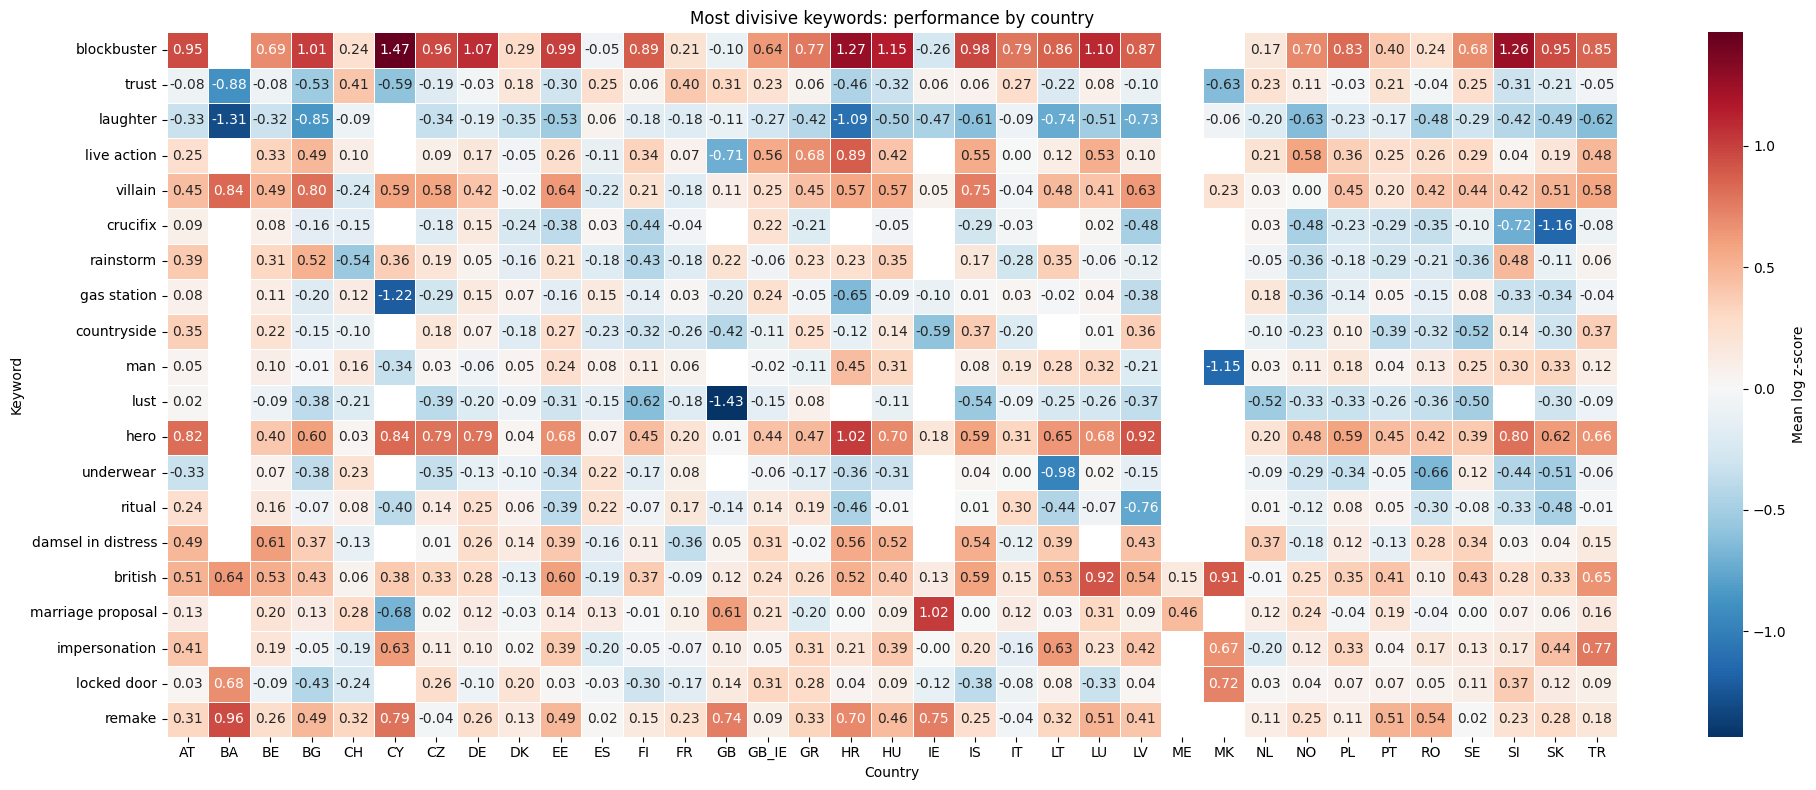

In [28]:
# Heatmap of the top 20 most divisive keywords × country.
top_divisive = kw_variance.head(20).index.tolist()

heatmap_kw = (
    kw_country[kw_country["keyword"].isin(top_divisive)]
    .pivot(index="keyword", columns="country", values="mean")
)

# Order keywords by variance, countries by the dendrogram order from earlier.
heatmap_kw = heatmap_kw.loc[top_divisive]

fig, ax = plt.subplots(figsize=(20, 8))
sns.heatmap(
    heatmap_kw,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    ax=ax,
    cbar_kws={"label": "Mean log z-score"}
)
ax.set_title("Most divisive keywords: performance by country")
ax.set_xlabel("Country")
ax.set_ylabel("Keyword")
plt.tight_layout()
plt.show()

Yes, partially — but with some interesting wrinkles.

**The Central/Northern mainstream bloc** (DE, GB_IE, CZ, HU, HR, BE, PL, etc.) shows the clearest alignment. These countries are consistently warm on "blockbuster", "villain", "hero", "remake", "live action" — they're the big commercial entertainment markets. Hungary and Croatia in particular light up bright red on these keywords. This group likes spectacle.

**The Balkan/small market group** is more mixed than expected. BA (Bosnia) is strongly positive on "villain", "locked door", "remake" but deeply negative on "laughter" and "trust". MK (North Macedonia) has some extreme values ("locked door" +0.72, "impersonation" +0.67) but these might be driven by small sample sizes — worth being cautious there.

**The left branch** (GB, FR, FI, IT, LV, SI, etc.) does show a pattern — they're generally cooler on the big commercial keywords. FR stands out as negative on "blockbuster" (-0.10), "live action" (+0.07), and "hero" (+0.01) while most of Europe is positive. Italy is similar. These markets seem to prefer less formulaic content.

**Where it breaks down a bit:** some individual countries defy their group. CY (Cyprus) is strongly positive on "blockbuster" (+1.47) but was placed in the smaller markets branch. AT (Austria) is consistently negative on almost everything divisive, which is unusual for the Central European group. And "laughter" is negative almost *everywhere* — that's not really divisive across groups, it's just universally weak, probably because comedy tagged with "laughter" tends to be low-quality slapstick.

**The most predictor-useful patterns** I see are: "blockbuster"/"hero"/"villain"/"remake" form a commercial-appeal axis that clearly separates markets, and "british"/"countryside" form a cultural-specificity axis. These two dimensions could be strong features.

Want to look at specific keywords more closely — maybe pick 3-4 and see their full country distribution? Or move on to the domestic vs. foreign analysis?

In [29]:
# Flag domestic vs foreign.
# A film is "domestic" when the country it's playing in matches its mainCountry.
# GB_IE needs special handling — treat it as domestic for both GB and IE origin films.
def is_domestic(row):
    origin = str(row["mainCountry"]).strip().upper()
    market = str(row["country"]).strip().upper()
    
    if market == origin:
        return True
    if market == "GB_IE" and origin in ("GB", "IE"):
        return True
    return False

df_long["is_domestic"] = df_long.apply(is_domestic, axis=1)

domestic_pct = df_long["is_domestic"].mean() * 100
print(f"Domestic rows: {df_long['is_domestic'].sum()} ({domestic_pct:.1f}%)")
print(f"Foreign rows:  {(~df_long['is_domestic']).sum()} ({100 - domestic_pct:.1f}%)")

print(f"\nMean z-score comparison:")
print(f"  Domestic: {df_long.loc[df_long['is_domestic'], 'admissions_zscore'].mean():.3f}")
print(f"  Foreign:  {df_long.loc[~df_long['is_domestic'], 'admissions_zscore'].mean():.3f}")

print(f"\nMean percentile comparison:")
print(f"  Domestic: {df_long.loc[df_long['is_domestic'], 'admissions_percentile'].mean():.1f}")
print(f"  Foreign:  {df_long.loc[~df_long['is_domestic'], 'admissions_percentile'].mean():.1f}")

Domestic rows: 1380 (6.2%)
Foreign rows:  20917 (93.8%)

Mean z-score comparison:
  Domestic: 0.168
  Foreign:  -0.011

Mean percentile comparison:
  Domestic: 56.1
  Foreign:  49.7


Mean z-score by cluster × domestic/foreign:

Cluster      Domestic    Foreign        Gap  Dom count  For count
-------------------------------------------------------
0               0.394      0.414     -0.020        200       3459
1               0.139     -0.032      0.171        272       4196
2               0.244     -0.147      0.391        226       3593
3              -0.110     -0.063     -0.047        196       2790
4               0.166     -0.198      0.364        288       4196
5               0.170      0.003      0.167        198       2683


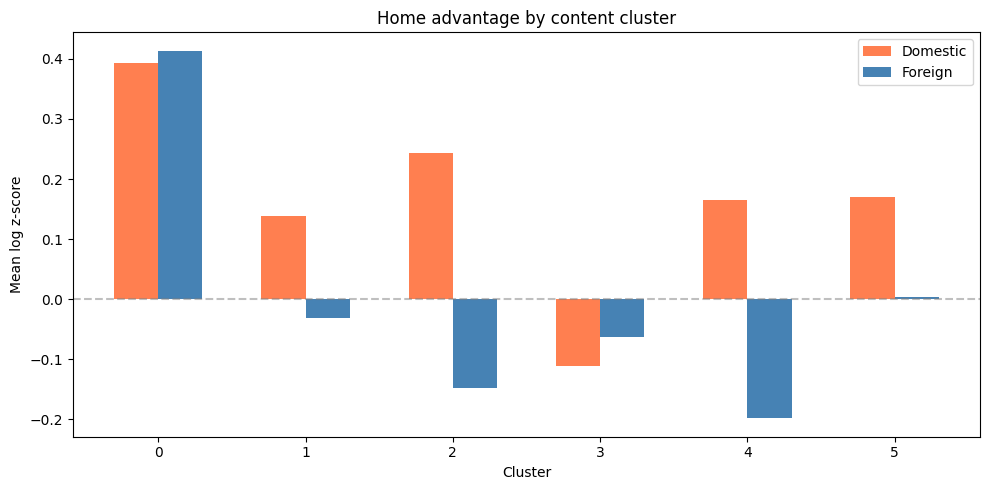

In [31]:
# Domestic vs foreign performance by cluster.
dom_by_cluster = (
    df_long.groupby(["cluster", "is_domestic"])["admissions_zscore"]
    .agg(["mean", "count"])
    .unstack(fill_value=0)
)

print("Mean z-score by cluster × domestic/foreign:\n")
print(f"{'Cluster':<10} {'Domestic':>10} {'Foreign':>10} {'Gap':>10} {'Dom count':>10} {'For count':>10}")
print("-" * 55)
for cluster in sorted(df_long["cluster"].unique()):
    dom = df_long[(df_long["cluster"] == cluster) & df_long["is_domestic"]]["admissions_zscore"]
    foreign = df_long[(df_long["cluster"] == cluster) & ~df_long["is_domestic"]]["admissions_zscore"]
    gap = dom.mean() - foreign.mean() if len(dom) > 0 else float("nan")
    print(f"{cluster:<10} {dom.mean():>10.3f} {foreign.mean():>10.3f} {gap:>10.3f} {len(dom):>10} {len(foreign):>10}")

# Visualize.
fig, ax = plt.subplots(figsize=(10, 5))
clusters = sorted(df_long["cluster"].unique())
dom_means = [df_long[(df_long["cluster"] == c) & df_long["is_domestic"]]["admissions_zscore"].mean() for c in clusters]
for_means = [df_long[(df_long["cluster"] == c) & ~df_long["is_domestic"]]["admissions_zscore"].mean() for c in clusters]

x = np.arange(len(clusters))
ax.bar(x - 0.15, dom_means, 0.3, label="Domestic", color="coral")
ax.bar(x + 0.15, for_means, 0.3, label="Foreign", color="steelblue")
ax.set_xlabel("Cluster")
ax.set_ylabel("Mean log z-score")
ax.set_title("Home advantage by content cluster")
ax.set_xticks(x)
ax.set_xticklabels(clusters)
ax.legend()
ax.axhline(y=0, color="grey", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

This is really telling. Let me link it back to the cluster profiles:

**Cluster 0 (Horror/Thriller/Supernatural)** — gap of -0.02, essentially zero. It actually performs *slightly better* abroad than at home. This confirms what the heatmap showed: horror is the most universal content type. It doesn't need cultural context to work — fear travels.

**Cluster 2 (Buddy comedy/Coming-of-age)** — biggest gap at +0.39. These films rely heavily on the home market. Makes sense: humor about friends, school, small-town life is deeply culturally specific. The Inbetweeners is hilarious in Britain but the jokes don't land the same way in Romania. And crucially, the foreign z-score is -0.15, meaning these films actively *under-perform* abroad.

**Cluster 4 (Romance/Relationship drama)** — second biggest gap at +0.36, similar story. Intimate relationship stories are rooted in local social norms, language nuance, and cultural expectations around love and marriage. They do okay at home (+0.17) but poorly abroad (-0.20).

**Cluster 1 (Serious drama/War/Historical)** and **Cluster 5 (Adventure/Fantasy/Family)** — moderate gaps around +0.17. These travel reasonably well but still get a home boost.

**Cluster 3 (Crime thriller/Detective)** — the odd one out with a gap of -0.05, and it's the only cluster that's *negative at home* (-0.11). This suggests these films under-perform everywhere, but slightly less so abroad. Possibly because many are lower-budget genre films that don't attract large audiences anywhere.

**Key takeaway for the predictor:** the domestic/foreign effect isn't uniform — it interacts strongly with content type. Your model needs a cluster × domestic interaction term, not just a single domestic flag. A comedy producer changing their setting from domestic to foreign should get a much bigger warning than a horror producer doing the same thing. Want to break this down further by country, or move on to another analysis?

In [32]:
from scipy.stats import entropy

# For each film, compute the distribution of admissions across countries.
def compute_universality(group):
    # Proportional share per country.
    shares = group["admissions"] / group["admissions"].sum()
    
    # Shannon entropy — higher = more evenly spread.
    ent = entropy(shares)
    
    # Normalize by max possible entropy (uniform across all countries).
    max_ent = np.log(len(shares))
    norm_entropy = ent / max_ent if max_ent > 0 else 0
    
    return pd.Series({
        "entropy": ent,
        "universality": norm_entropy,  # 0 = all in one country, 1 = perfectly even
        "n_countries": len(group),
        "total_admissions": group["admissions"].sum(),
        "top_country_share": shares.max(),
        "top_country": group.loc[shares.idxmax(), "country"]
    })

df_universality = (
    df_long.groupby(["titleId", "originalTitle", "cluster", "mainCountry", "firstLanguage"])
    .apply(compute_universality)
    .reset_index()
)

print(f"Films with universality scores: {len(df_universality)}")
print(f"\nUniversality distribution:")
print(df_universality["universality"].describe().round(3))

print(f"\n\nMost universal films (top 10):")
print(df_universality.nlargest(10, "universality")[
    ["originalTitle", "cluster", "universality", "n_countries", "top_country_share", "top_country"]
].to_string(index=False))

print(f"\n\nLeast universal films (bottom 10):")
print(df_universality.nsmallest(10, "universality")[
    ["originalTitle", "cluster", "universality", "n_countries", "top_country_share", "top_country"]
].to_string(index=False))

Films with universality scores: 1840

Universality distribution:
count    1840.000
mean        0.469
std         0.296
min         0.000
25%         0.189
50%         0.571
75%         0.711
max         0.999
Name: universality, dtype: float64


Most universal films (top 10):
                             originalTitle  cluster  universality  n_countries  top_country_share top_country
                       The Girl in a Swing        2      0.999421            2           0.514170          IT
                         Follow That Camel        5      0.999203            2           0.516615          SE
                             London Fields        1      0.998156            2           0.525272          LT
                  The Evil of Frankenstein        3      0.996792            2           0.533333          NO
                                  The Twin        3      0.995507            2           0.539439       GB_IE
                                  Saturn 3        3      0.9952

In [33]:
# Filter to films that played in enough countries for universality to be meaningful.
MIN_COUNTRIES = 15

df_univ = df_universality[df_universality["n_countries"] >= MIN_COUNTRIES].copy()

print(f"Films with {MIN_COUNTRIES}+ countries: {len(df_univ)} / {len(df_universality)}")
print(f"\nUniversality distribution (filtered):")
print(df_univ["universality"].describe().round(3))

print(f"\n\nMost universal films (top 10):")
print(df_univ.nlargest(10, "universality")[
    ["originalTitle", "cluster", "universality", "n_countries", "top_country_share", "top_country"]
].to_string(index=False))

print(f"\n\nLeast universal films (bottom 10):")
print(df_univ.nsmallest(10, "universality")[
    ["originalTitle", "cluster", "universality", "n_countries", "top_country_share", "top_country"]
].to_string(index=False))

# Now the interesting question: does universality vary by cluster?
print(f"\n\nMean universality by cluster:")
cluster_univ = df_univ.groupby("cluster")["universality"].agg(["mean", "std", "count"]).round(3)
print(cluster_univ)


Films with 15+ countries: 703 / 1840

Universality distribution (filtered):
count    703.000
mean       0.657
std        0.123
min        0.140
25%        0.613
50%        0.688
75%        0.744
max        0.875
Name: universality, dtype: float64


Most universal films (top 10):
                  originalTitle  cluster  universality  n_countries  top_country_share top_country
                        Flyboys        2      0.875050           15           0.172341          ES
               The Gamma People        3      0.862585           16           0.190302          FR
          Nymphomaniac: Vol. II        4      0.853121           26           0.136180          FR
                Man on the Moon        5      0.852200           18           0.213197          ES
               Rakkaus on aarre        4      0.842152           16           0.174627          FR
Garfield: A Tale of Two Kitties        0      0.841132           27           0.134833       GB_IE
           Nymphomaniac: Vo

This makes much more sense now. A few observations:
The extremes are intuitive. The most universal films are things like Angry Birds, Garfield — content that doesn't need cultural context. The least universal are almost all French films (Le dîner de cons, Taxi, Ne le dis à personne) with 80-90% of their audience in France, plus The Inbetweeners which is 90% GB_IE. These are culturally specific hits that got wide distribution but only really connected at home.
Cluster universality mostly confirms the domestic/foreign findings, but with a twist. Cluster 3 (crime thriller) is actually the most universal at 0.696, not cluster 0 (horror) at 0.681. Remember that cluster 3 had a weird domestic/foreign pattern — negative everywhere, but slightly less negative abroad. Now we see why: these films don't do great anywhere, but they spread their modest audience very evenly. Cluster 5 (adventure/fantasy/family) is the least universal at 0.617, which is surprising — you'd expect family blockbusters to travel. Possibly pulled down by culturally specific children's content.
But the differences are small — the range is only 0.617 to 0.696. Content cluster alone doesn't strongly predict universality, which means other factors matter more. Let's see what does:

In [35]:
# Bring back film-level features from the original df.
film_features = df[["titleId", "imdbRating", "numberOfVotes", "runtimeMinutes"]].drop_duplicates("titleId")
df_univ = df_univ.merge(film_features, on="titleId", how="left")

print("Correlation with universality:")
print(f"  IMDb rating:      {df_univ['imdbRating'].corr(df_univ['universality']):.3f}")
print(f"  Number of votes:  {df_univ['numberOfVotes'].corr(df_univ['universality']):.3f}")
print(f"  Total admissions: {df_univ['total_admissions'].corr(df_univ['universality']):.3f}")
print(f"  N countries:      {df_univ['n_countries'].corr(df_univ['universality']):.3f}")
print(f"  Runtime:          {df_univ['runtimeMinutes'].corr(df_univ['universality']):.3f}")

# Universality by origin language.
lang_univ = (
    df_univ.groupby("firstLanguage")["universality"]
    .agg(["mean", "count"])
    .query("count >= 10")
    .sort_values("mean", ascending=False)
    .round(3)
)
print(f"\nUniversality by origin language (10+ films):")
print(lang_univ)

# Universality by origin country.
country_univ = (
    df_univ.groupby("mainCountry")["universality"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
    .round(3)
)
print(f"\nUniversality by origin country:")
print(country_univ)

Correlation with universality:
  IMDb rating:      -0.151
  Number of votes:  0.048
  Total admissions: 0.096
  N countries:      0.287
  Runtime:          -0.020

Universality by origin language (10+ films):
                mean  count
firstLanguage              
en             0.675    545
es             0.626     11
it             0.615     17
de             0.551     25
fr             0.529     55

Universality by origin country:
              mean  count
mainCountry              
UA           0.778      1
GR           0.763      7
FI           0.757      8
RS           0.752      2
AT           0.750      2
RO           0.740      2
HU           0.734      2
DK           0.732     17
CH           0.691      6
GB           0.676    333
NO           0.675      6
IE           0.673     33
BE           0.666     10
SE           0.665     10
CZ           0.659      8
PL           0.659      5
NL           0.649      2
IT           0.643     30
DE           0.642     78
ES           0.6

Clear findings here:

**Language is the strongest predictor of universality.** English-language films average 0.675, then Spanish (0.626) and Italian (0.615), with French at the bottom (0.529). This makes intuitive sense — English is widely understood or at least culturally familiar across Europe, so English-language films spread more evenly. French films, despite having wide distribution, concentrate their audience heavily in France (as we saw in the bottom 10 list).

**IMDb rating is negatively correlated (-0.15).** This is counterintuitive at first, but it makes sense: highly-rated films tend to be artsy, niche, or culturally specific — the kind of film that wins at Cannes but only really connects in a few markets. Mass-appeal blockbusters often have mediocre ratings (6-7 range) but spread evenly everywhere.

**Number of countries (0.287) is the strongest correlation**, but that's partly mechanical — more countries means more chances to spread out.

**Total admissions barely matter (0.096).** A film can be huge but concentrated (French hits) or modest but evenly spread. Size and universality are nearly independent.

**Origin country confirms the language pattern.** France is dead last at 0.581 among countries with meaningful counts. GB is at 0.676, and the small countries at the top (GR, FI, DK) should be taken with a grain of salt due to low counts — though it's interesting that films from small markets *that do get wide distribution* tend to spread evenly, probably because they have no large home market to concentrate in.

**Key takeaway for the predictor:** language should be a first-class feature, possibly more important than origin country. An English-language film made in France might behave very differently from a French-language film made in France. Want to test that hypothesis next, or move on to something else?

In [36]:
# Compare: is it language or country that drives universality?
# Focus on the biggest origin country (France) where we have both
# French-language and non-French-language films.

# First, check which origin countries have films in multiple languages.
lang_by_country = (
    df_univ.groupby(["mainCountry", "firstLanguage"])
    .size()
    .reset_index(name="count")
    .query("count >= 5")
    .sort_values(["mainCountry", "count"], ascending=[True, False])
)
print("Origin country × language combinations (5+ films):")
print(lang_by_country.to_string(index=False))

# Now the key test: same country, different language.
print("\n\nUniversality by country × language (5+ films):")
country_lang_univ = (
    df_univ.groupby(["mainCountry", "firstLanguage"])["universality"]
    .agg(["mean", "count"])
    .query("count >= 5")
    .sort_values("mean", ascending=False)
    .round(3)
)
print(country_lang_univ)

# Direct comparison: English vs non-English, controlling for country.
# For countries that produce both.
both = (
    df_univ.assign(is_english=df_univ["firstLanguage"] == "en")
    .groupby(["mainCountry", "is_english"])["universality"]
    .agg(["mean", "count"])
    .unstack(fill_value=0)
)
# Only show countries with 5+ films in both categories.
mask = (both[("count", True)] >= 5) & (both[("count", False)] >= 5)
both = both[mask].copy()

if len(both) > 0:
    print("\n\nEnglish vs non-English from the SAME country:")
    for country in both.index:
        en_mean = both.loc[country, ("mean", True)]
        non_en_mean = both.loc[country, ("mean", False)]
        en_n = int(both.loc[country, ("count", True)])
        non_en_n = int(both.loc[country, ("count", False)])
        gap = en_mean - non_en_mean
        print(f"  {country}: English={en_mean:.3f} (n={en_n})  Non-English={non_en_mean:.3f} (n={non_en_n})  Gap={gap:+.3f}")
else:
    print("\n\nNo countries with 5+ films in both English and non-English.")

Origin country × language combinations (5+ films):
mainCountry firstLanguage  count
         BE            en      7
         CH            en      5
         CZ            en      5
         DE            en     55
         DE            de     22
         DK            en     12
         DK            da      5
         ES            en     17
         ES            es      9
         FI            en      7
         FR            en     59
         FR            fr     51
         GB            en    327
         GR            el      7
         IE            en     31
         IT            it     17
         IT            en     13
         NO            no      5
         PL            pl      5
         SE            sv      8


Universality by country × language (5+ films):
                            mean  count
mainCountry firstLanguage              
DK          en             0.786     12
GR          el             0.763      7
FI          en             0.745      7
CZ     

This is a clean result. The bottom section is the key finding:

**Language wins over country, consistently.** In every country except GB (where nearly everything is English anyway), making a film in English increases its universality. The effect size varies:

- **Denmark: +0.183** — biggest gap. A Danish-language film from Denmark spreads much less evenly than an English-language one from Denmark.
- **Germany: +0.156** — strong effect. German-language films concentrate heavily in DE/AT/CH, while English-language German productions spread across Europe.
- **France: +0.101** — meaningful gap. French-language films from France average 0.523 (the lowest in the whole table), while English-language French productions jump to 0.630. Still not as universal as English films from GB or DE, which suggests country of origin *also* matters — there may be a "French production style" effect on top of language.
- **Italy: +0.064** and **Spain: +0.042** — smaller but still positive.
- **GB: -0.009** — essentially no difference, which makes sense as a control. There's no "language switch" to make in a country that already produces in English.

**The France result is especially interesting for your predictor.** A French-made English-language film (0.630) is still less universal than a German-made English-language film (0.688) or a Danish one (0.786). So language isn't the whole story — origin country has an independent effect even after controlling for language. Your predictor should include both.

**One more nuance:** look at Greek films in Greek (0.763) and Norwegian films in Norwegian (0.676) — both surprisingly high. These are small-count samples but it suggests that films from small markets that manage to get wide distribution are inherently more universal, regardless of language. Possibly a selection effect — only the most broadly appealing small-language films get picked up for international distribution.

**For the predictor architecture this means:** you want at minimum three separate inputs: content features (cluster/keywords), origin country, and language — and ideally an interaction between language and market country (a French film plays differently in Belgium vs. Finland, but an English film plays more similarly across both). Want to explore that language × market interaction, or move on to another analysis?

Languages with 30+ films: ['en', 'fr', 'it', 'de', 'es']


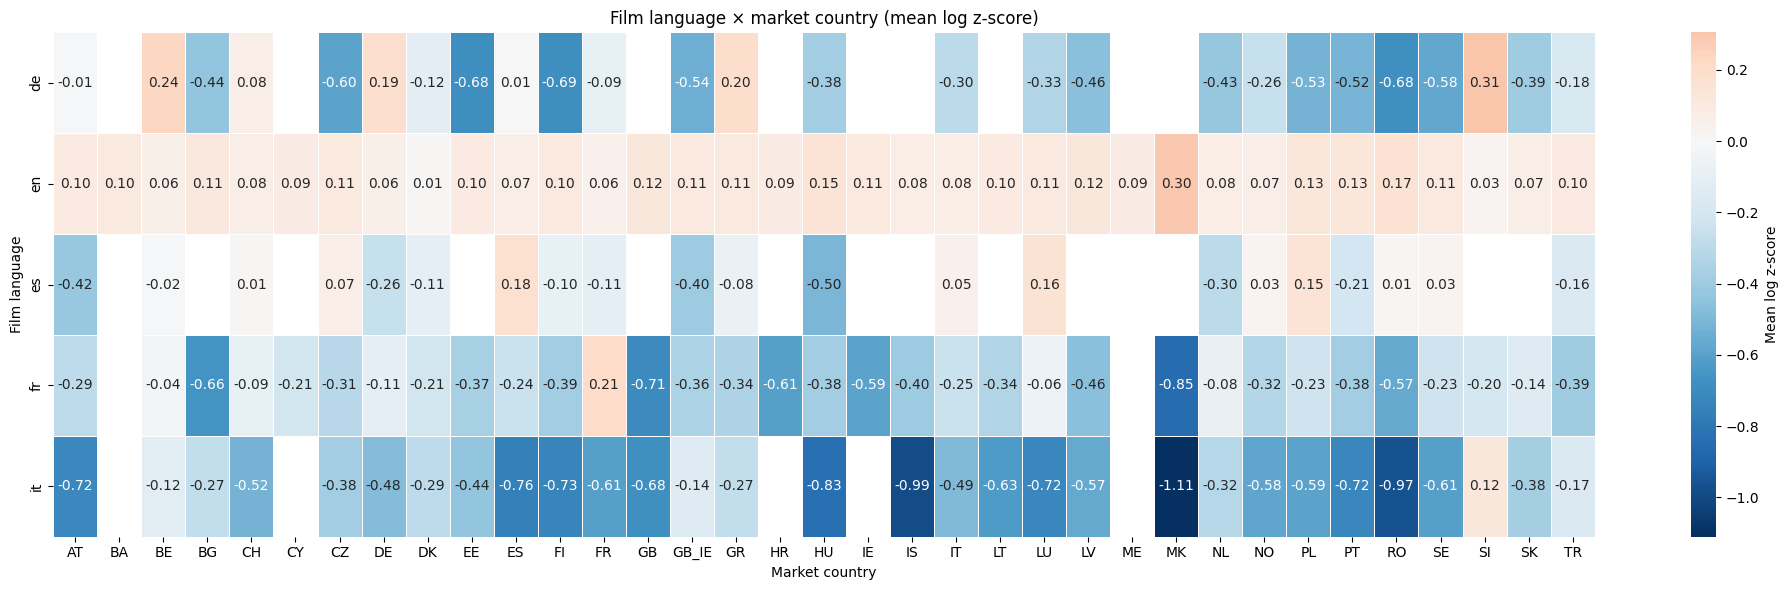

In [37]:
# Mean z-score by film language × market country.
# Only keep languages with enough films.
MIN_FILMS_LANG = 30
lang_counts = df_long.drop_duplicates("titleId")["firstLanguage"].value_counts()
valid_langs = lang_counts[lang_counts >= MIN_FILMS_LANG].index.tolist()

df_lang = df_long[df_long["firstLanguage"].isin(valid_langs)].copy()
print(f"Languages with {MIN_FILMS_LANG}+ films: {valid_langs}")

# Pivot: language × market country.
lang_market = (
    df_lang.groupby(["firstLanguage", "country"])["admissions_zscore"]
    .agg(["mean", "count"])
    .reset_index()
)

# Require minimum observations per cell.
lang_market = lang_market[lang_market["count"] >= 10].copy()

lang_heatmap = lang_market.pivot(index="firstLanguage", columns="country", values="mean")

fig, ax = plt.subplots(figsize=(20, 6))
sns.heatmap(
    lang_heatmap,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    ax=ax,
    cbar_kws={"label": "Mean log z-score"}
)
ax.set_title("Film language × market country (mean log z-score)")
ax.set_xlabel("Market country")
ax.set_ylabel("Film language")
plt.tight_layout()
plt.show()

This is very clear. A few key patterns:

**English is the only language that's positive everywhere.** Every single cell in the English row is between +0.01 and +0.30. No market penalizes English-language films. This is the baseline that all other languages are competing against.

**French has exactly one corridor: France (+0.21) and Belgium (-0.04, nearly neutral).** Everywhere else is solidly negative, often deeply so: GB (-0.71), GB_IE (-0.36), Finland (-0.39), Iceland (-0.85). French-language films face a steep penalty across most of Europe.

**German shows a clear corridor too: Austria (-0.01, neutral) and Switzerland (+0.08).** But interestingly Germany itself is blank or missing — probably because we're looking at z-scores within country, and German films are so common in Germany that they're just "average." Everywhere outside the German-speaking world is negative, especially Bulgaria (-0.44), Finland (-0.69), and Portugal (-0.68).

**Italian is the worst-traveling language.** Deeply negative almost everywhere, including some extreme values: Iceland (-0.99), MK (-1.11), Romania (-0.97), Portugal (-0.72). Even in nearby markets like Austria (-0.72) and Switzerland (-0.52) it struggles. Italian-language films are essentially a domestic product.

**Spanish sits between French and Italian.** Moderate negatives everywhere except a few markets. Interestingly it shows a slight positive in Italy (+0.16) and Luxembourg (+0.16) but those could be noise.

**The key predictor insight:** language creates a "floor" for each market. An Italian-language film starts at roughly -0.5 to -1.0 in most non-Italian markets before content even matters. Your predictor should model this as a strong baseline effect that content features can then adjust up or down from. English effectively has no floor penalty, which is why English-language films appear more universal — it's not that their content is better, it's that they don't start in a hole.

Ready for the next one — keyword × domestic/foreign?

In [38]:
# For each keyword, compare mean z-score when playing domestic vs foreign.
# Reuse the parsed keywords from earlier.
df_kw_dom = df_long.explode("keywords_list")
df_kw_dom = df_kw_dom[df_kw_dom["keywords_list"].isin(valid_keywords)].copy()
df_kw_dom = df_kw_dom.rename(columns={"keywords_list": "keyword"})

kw_dom = (
    df_kw_dom.groupby(["keyword", "is_domestic"])["admissions_zscore"]
    .agg(["mean", "count"])
    .unstack(fill_value=0)
)

# Flatten column names.
kw_dom.columns = [f"{stat}_{('domestic' if dom else 'foreign')}" for stat, dom in kw_dom.columns]

# Only keep keywords with enough observations in BOTH categories.
MIN_DOM = 10
MIN_FOR = 50
kw_dom = kw_dom[
    (kw_dom["count_domestic"] >= MIN_DOM) &
    (kw_dom["count_foreign"] >= MIN_FOR)
].copy()

kw_dom["gap"] = kw_dom["mean_domestic"] - kw_dom["mean_foreign"]
kw_dom = kw_dom.sort_values("gap", ascending=False)

print(f"Keywords with enough domestic + foreign data: {len(kw_dom)}")

print(f"\n\nTop 15 'stays home' keywords (biggest domestic advantage):")
print(kw_dom.head(15)[["mean_domestic", "mean_foreign", "gap", "count_domestic", "count_foreign"]].round(3).to_string())

print(f"\n\nTop 15 'travels well' keywords (smallest or negative gap):")
print(kw_dom.tail(15)[["mean_domestic", "mean_foreign", "gap", "count_domestic", "count_foreign"]].round(3).to_string())

Keywords with enough domestic + foreign data: 723


Top 15 'stays home' keywords (biggest domestic advantage):
                     mean_domestic  mean_foreign    gap  count_domestic  count_foreign
keyword                                                                               
trust                        0.626        -0.023  0.649              52           1044
split screen                 0.527        -0.093  0.620              38            805
alcohol                      0.549        -0.066  0.615              44            799
promise                      0.649         0.054  0.596              54           1097
cheating wife                0.117        -0.476  0.594              43            548
marriage proposal            0.652         0.077  0.576              65           1219
german                       0.559         0.003  0.556              62           1233
handshake                    0.480        -0.072  0.552              46            877
coffee             

Really clean results. The two lists tell completely different stories:

**"Stays home" keywords are about everyday domestic life.** Trust, alcohol, promises, marriage proposals, coffee, kitchen, birthdays, psychological drama — these are intimate, culturally embedded themes. A film about a marriage proposal resonates because the audience shares the same social norms around marriage. "German" as a keyword is the most literal version of this — films that are explicitly about German identity do well in Germany and nowhere else. "Cheating wife" is interesting: negative everywhere (-0.48 abroad) but slightly positive domestically — audiences engage with infidelity stories rooted in their own culture but aren't interested in foreign ones.

**"Travels well" keywords are about spectacle, genre, and archetypes.** Monsters, creatures, villains, kings, missions, espionage, blockbusters, damsels in distress — these are universal storytelling elements that don't need cultural context. "Monster" has the biggest negative gap (-0.33): it actually does *better* abroad than at home. Same for "creature" (-0.29) and "villain" (-0.18). These films benefit from being foreign — exoticism adds rather than subtracts.

**The practical takeaway for your predictor is very concrete.** If someone is writing a tagline and wants international reach, the model should nudge them toward archetypal, high-concept elements (villains, missions, creatures) and away from culturally specific domestic themes (trust, promises, kitchen drama). The gap values themselves could become feature weights — a "travelability score" computed from the film's keywords.

Ready for the last one — origin country × market affinity?

Origin countries with 30+ films: ['GB', 'FR', 'DE', 'IT', 'ES', 'IE', 'SE', 'DK']


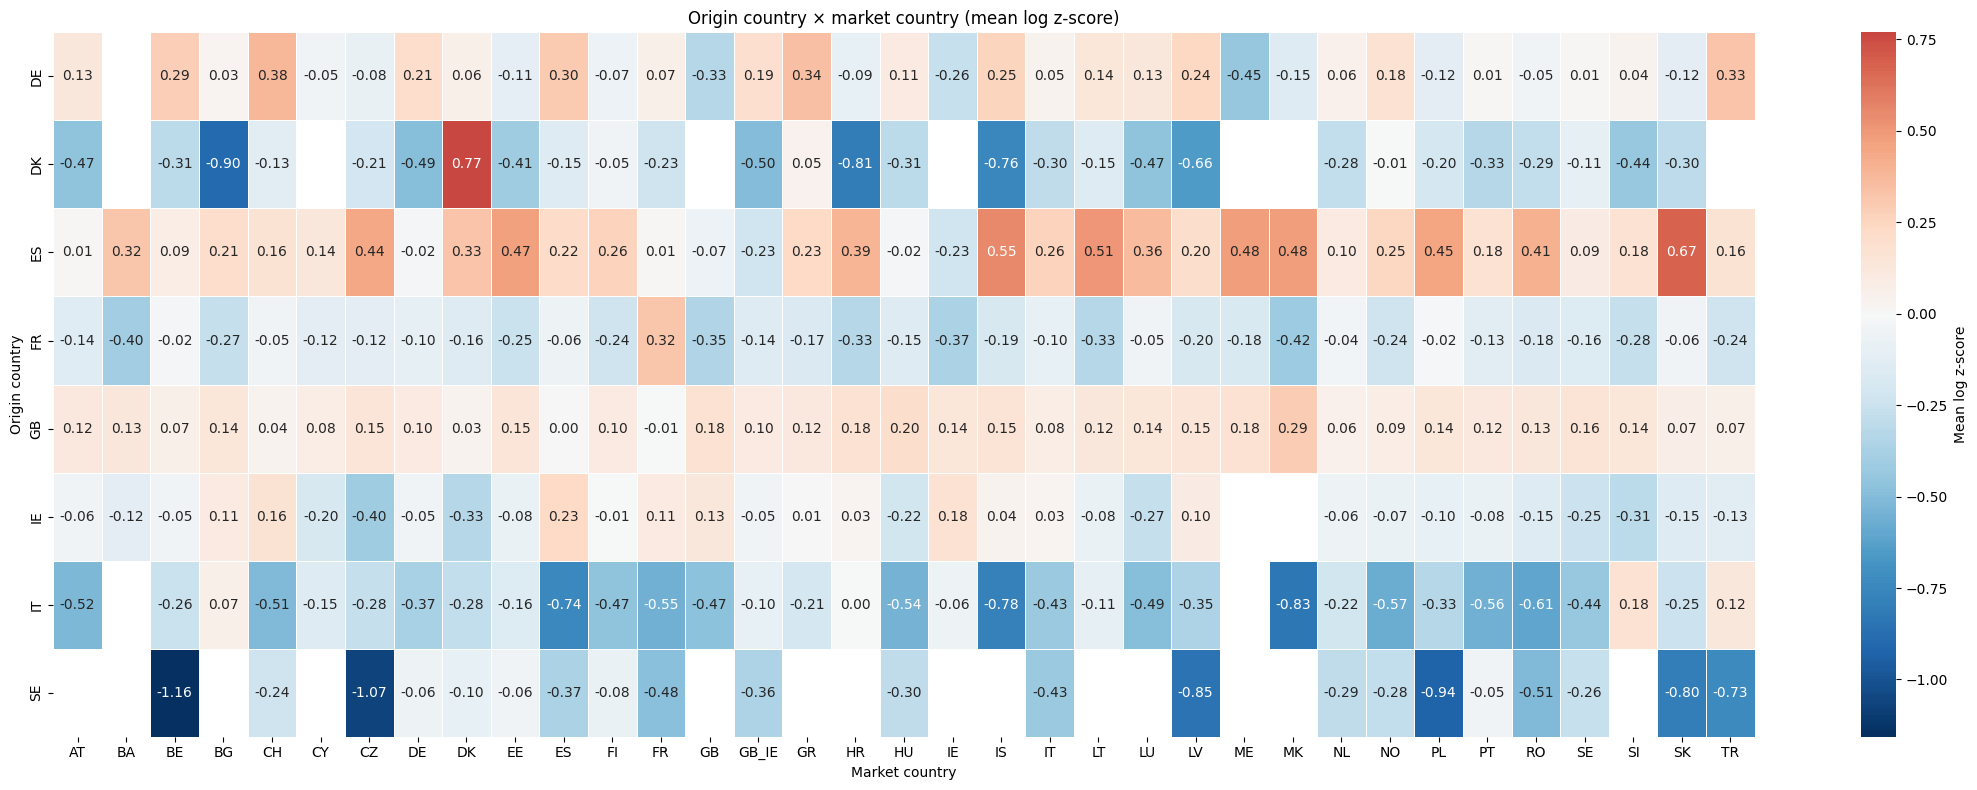

In [39]:
# Mean z-score by origin country × market country.
# Only keep origin countries with enough films.
MIN_ORIGIN_FILMS = 30
origin_counts = df_long.drop_duplicates("titleId")["mainCountry"].value_counts()
valid_origins = origin_counts[origin_counts >= MIN_ORIGIN_FILMS].index.tolist()

df_origin = df_long[df_long["mainCountry"].isin(valid_origins)].copy()
print(f"Origin countries with {MIN_ORIGIN_FILMS}+ films: {valid_origins}")

# Pivot: origin country × market country.
origin_market = (
    df_origin.groupby(["mainCountry", "country"])["admissions_zscore"]
    .agg(["mean", "count"])
    .reset_index()
)

# Require minimum observations per cell.
origin_market = origin_market[origin_market["count"] >= 10].copy()

origin_heatmap = origin_market.pivot(index="mainCountry", columns="country", values="mean")

fig, ax = plt.subplots(figsize=(22, 8))
sns.heatmap(
    origin_heatmap,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    ax=ax,
    cbar_kws={"label": "Mean log z-score"}
)
ax.set_title("Origin country × market country (mean log z-score)")
ax.set_xlabel("Market country")
ax.set_ylabel("Origin country")
plt.tight_layout()
plt.show()

Very rich heatmap. Here's what jumps out:

**GB is the only origin country that's positive almost everywhere.** Consistently light red across the board, from +0.03 to +0.29. British films are the most broadly accepted across Europe. This combines the English language advantage with a strong production reputation. The biggest fans are MK (+0.29), Iceland (+0.15), and the Netherlands (+0.14).

**France is negative everywhere.** Not a single positive cell. This is striking — French films under-perform in every European market. The worst are Hungary (-0.37), MK (-0.42), GB (-0.35), and Bosnia (-0.40). Even Belgium, which shares the French language, is only -0.02. This goes beyond language — there's something about French production style that doesn't travel.

**Italy is even worse.** Deeply negative almost everywhere, with extreme values in Iceland (-0.78), Finland (-0.74), Austria (-0.52), MK (-0.83). Italian-language films face the steepest penalty of any origin country.

**Spain is the surprise winner after GB.** Positive in most markets, with some strong values: Slovakia (+0.67), Iceland (+0.55), Italy (+0.51), Luxembourg (+0.36). Spanish films travel well beyond their language corridor — this could be content-driven (Spanish cinema produces a lot of horror and thriller which we know travels well).

**Denmark shows a fascinating split.** Huge positive in Denmark itself (+0.77, the strongest domestic effect on the whole map) but deeply negative almost everywhere else: Bulgaria (-0.90), CZ (-1.07), Hungary (-0.81), Latvia (-0.66). Danish films are the most "stay at home" of any origin, even more than French.

**Germany is mildly positive in many markets** — Switzerland (+0.38), Greece (+0.34), Turkey (+0.33), Bosnia (+0.29). The German-speaking corridor (AT, CH) is there but the appeal extends further. Possibly driven by German-made English-language productions.

**Sweden has very few positive cells** and some extreme negatives: Bosnia (-1.16), CZ (-1.07), Latvia (-0.85), Poland (-0.94). Swedish films travel poorly.

**Ireland is mostly flat** — hovering around zero with a slight negative lean. Not penalized but not sought out either.

**Key patterns for the predictor:**

First, there are clear **geographic affinity corridors** beyond language: Spain → Italy, Germany → Greece/Turkey, GB → everywhere. Second, there's a strong **"penalty floor" by origin** — Italian and Danish origin impose a baseline penalty that content would need to overcome. Third, **GB origin is essentially a free pass** — it adds a small positive everywhere, which stacks on top of the English language advantage.

Your predictor should include origin country as a feature, separate from language, with country-pair-specific coefficients. A simple approach would be an origin × market interaction matrix exactly like this heatmap, used as a lookup table in the model.

That's all four analyses done. Ready to start assembling the predictor features?

**SUMMMARY

**What we found.** European film performance is shaped by several layered effects that interact with each other. The most fundamental divide is language: English-language films perform consistently positively across every market, while French, German, and especially Italian-language films face steep penalties outside their linguistic corridors (French in Belgium/France, German in Austria/Switzerland). Origin country adds an independent effect on top of language — British films are mildly positive everywhere, Spanish films travel surprisingly well (likely because Spain produces genre content that crosses borders), while Danish and Swedish films are heavily domestic despite sometimes being in English. Content type matters but less than you might expect: horror/thriller (cluster 0) is the only content category that's uniformly positive across Europe and is essentially immune to the domestic/foreign penalty, while buddy comedy (cluster 2) and romance (cluster 4) rely heavily on home markets and lose 0.3–0.4 z-score points abroad. At the keyword level, the divide is between archetypal spectacle elements (monsters, villains, missions, creatures) which actually perform *better* abroad than at home, and culturally embedded domestic themes (trust, marriage proposals, kitchen, psychological drama) which boost a film at home but penalize it internationally. Country-level taste clustering revealed that European markets don't group neatly by geography or language — Portugal clusters with Sweden, Netherlands with Romania — suggesting that cultural preferences for content types cut across traditional regional boundaries. Film quality (IMDb rating) is slightly negatively correlated with universality, meaning critically acclaimed films tend to be more culturally niche while broadly-distributed audience pleasers score closer to average.

**What this means for the predictor.** The model needs at minimum five separate input channels: content features (cluster membership and individual keywords), origin country, film language, target market country, and a domestic/foreign flag. These should not be treated as additive — the key interactions are what drive performance. Language × market gives you the baseline floor (an Italian-language film starts at -0.5 in most non-Italian markets), origin × market adjusts that floor up or down (Spanish origin lifts it, Danish origin pushes it further down), content cluster × domestic/foreign determines how much home advantage the film gets (huge for comedy, zero for horror), and individual keywords provide the fine-grained adjustment (adding "monster" or "villain" nudges the prediction upward for foreign markets, while "marriage proposal" or "trust" nudges it upward for the domestic market only). The architecture should probably be a two-stage model: first predict a baseline performance for each market from language, origin, and market identity, then adjust that baseline using content features and their interactions with the target market. This separation mirrors how the effects actually work in the data — language and origin set the floor, content determines how far above or below that floor you land. For the interactive "change Czechia to Poland" feature, this means the model can show the user exactly which effects are shifting: the origin × market affinity changes, the domestic flag might flip, and the language corridor effect adjusts, while the content contribution stays fixed.

** PREDICTOR

The idea is to build a model where a filmmaker can input their film's characteristics — its plot description, genre, keywords, language, country of origin — and get a predicted performance profile across European markets. The key interactive element is that they can tweak inputs and see how predictions shift: "what if I change the setting from Czechia to Poland?", "what if I shoot in English instead of French?", "what if I lean the tagline more toward thriller elements and away from domestic drama?"
So concretely, the model takes in:

Content features → cluster probabilities + individual keywords
Origin country → where the film is produced
Film language → what language it's shot in
Target market → which country you want to predict for

And outputs a predicted z-score (or percentile) for each European market, which can then be converted back to estimated admissions by multiplying by market size.
The analyses we just did essentially mapped out the main effects the model needs to capture: the language floor, the origin × market affinity, the content cluster effect, the domestic/foreign penalty by content type, and the keyword-level adjustments.
Before I start writing cells — one design question for your group: do you want a single interpretable model (like a linear regression with interaction terms, where you can explain every coefficient in a report) or a better-performing but less explainable model (like gradient boosted trees or a small neural net)? Given this is a university project, I'd lean toward interpretable — but what does your group prefer?

In [40]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")

# Start from df_long which has one row per film × market country.
# Target variable.
y = df_long["admissions_zscore"].values

print(f"Total rows (film × market pairs): {len(df_long)}")
print(f"Target variable stats:")
print(f"  Mean: {y.mean():.3f}")
print(f"  Std:  {y.std():.3f}")

Total rows (film × market pairs): 22297
Target variable stats:
  Mean: -0.000
  Std:  0.999


In [43]:
# Block 1: Cluster (one-hot).
cluster_dummies = pd.get_dummies(df_long["cluster"], prefix="cluster")

# Block 2: Market country (one-hot).
market_dummies = pd.get_dummies(df_long["country"], prefix="market")

# Block 3: Origin country (one-hot).
origin_dummies = pd.get_dummies(df_long["mainCountry"], prefix="origin")

# Block 4: Film language (one-hot).
lang_dummies = pd.get_dummies(df_long["firstLanguage"], prefix="lang")

# Block 5: Domestic flag.
domestic_flag = df_long["is_domestic"].astype(int).to_frame("is_domestic")

# Block 6: Numeric features.
numeric_features = df_long[["imdbRating", "runtimeMinutes"]].copy()
numeric_features = numeric_features.fillna(numeric_features.median())

# Verify shapes.
print(f"Cluster dummies:  {cluster_dummies.shape}")
print(f"Market dummies:   {market_dummies.shape}")
print(f"Origin dummies:   {origin_dummies.shape}")
print(f"Language dummies: {lang_dummies.shape}")
print(f"Domestic flag:    {domestic_flag.shape}")
print(f"Numeric features: {numeric_features.shape}")

Cluster dummies:  (22297, 6)
Market dummies:   (22297, 35)
Origin dummies:   (22297, 29)
Language dummies: (22297, 43)
Domestic flag:    (22297, 1)
Numeric features: (22297, 2)


In [44]:
# Train/test split — split by FILM not by row, to avoid leakage.
film_ids = df_long["titleId"].unique()
train_films, test_films = train_test_split(film_ids, test_size=0.2, random_state=42)

train_mask = df_long["titleId"].isin(train_films)
test_mask = df_long["titleId"].isin(test_films)

print(f"Train films: {len(train_films)}, Test films: {len(test_films)}")
print(f"Train rows:  {train_mask.sum()}, Test rows:  {test_mask.sum()}")

# Define feature blocks to add incrementally.
blocks = {
    "market": market_dummies,
    "+ origin": pd.concat([market_dummies, origin_dummies], axis=1),
    "+ language": pd.concat([market_dummies, origin_dummies, lang_dummies], axis=1),
    "+ cluster": pd.concat([market_dummies, origin_dummies, lang_dummies, cluster_dummies], axis=1),
    "+ domestic": pd.concat([market_dummies, origin_dummies, lang_dummies, cluster_dummies, domestic_flag], axis=1),
    "+ numeric": pd.concat([market_dummies, origin_dummies, lang_dummies, cluster_dummies, domestic_flag, numeric_features], axis=1),
}

print(f"\n{'Model':<20} {'Features':>8} {'Train R²':>10} {'Test R²':>10} {'Test RMSE':>10}")
print("-" * 62)

for name, X in blocks.items():
    X_train = X[train_mask].values
    X_test = X[test_mask].values
    y_train = y[train_mask]
    y_test = y[test_mask]
    
    model = Ridge(alpha=1.0)
    model.fit(X_train, y_train)
    
    train_r2 = model.score(X_train, y_train)
    test_r2 = model.score(X_test, y_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
    
    print(f"{name:<20} {X.shape[1]:>8} {train_r2:>10.4f} {test_r2:>10.4f} {test_rmse:>10.4f}")

Train films: 1472, Test films: 368
Train rows:  17605, Test rows:  4692

Model                Features   Train R²    Test R²  Test RMSE
--------------------------------------------------------------
market                     35     0.0002    -0.0021     1.0165
+ origin                   64     0.0388     0.0215     1.0044
+ language                107     0.0594     0.0327     0.9987
+ cluster                 113     0.0809     0.0716     0.9784
+ domestic                114     0.0844     0.0757     0.9762
+ numeric                 116     0.0957     0.0651     0.9818


In [46]:
# Add interaction terms — this is where our analysis showed the signal lives.

# Interaction 1: Language × Market.
lang_vals = lang_dummies.values
market_vals = market_dummies.values
lang_market_cols = [f"{l}_x_{m}" for l in lang_dummies.columns for m in market_dummies.columns]
lang_market_interaction = pd.DataFrame(
    (lang_vals[:, :, None] * market_vals[:, None, :]).reshape(len(df_long), -1),
    columns=lang_market_cols,
    index=df_long.index
)

# Interaction 2: Origin × Market.
origin_vals = origin_dummies.values
origin_market_cols = [f"{o}_x_{m}" for o in origin_dummies.columns for m in market_dummies.columns]
origin_market_interaction = pd.DataFrame(
    (origin_vals[:, :, None] * market_vals[:, None, :]).reshape(len(df_long), -1),
    columns=origin_market_cols,
    index=df_long.index
)

# Interaction 3: Cluster × Domestic.
cluster_domestic_interaction = pd.DataFrame(
    cluster_dummies.values * domestic_flag.values,
    columns=[f"{c}_x_domestic" for c in cluster_dummies.columns],
    index=df_long.index
)

print(f"Language × Market interactions:  {lang_market_interaction.shape}")
print(f"Origin × Market interactions:    {origin_market_interaction.shape}")
print(f"Cluster × Domestic interactions: {cluster_domestic_interaction.shape}")

# Build models incrementally.
base = pd.concat([market_dummies, origin_dummies, lang_dummies, cluster_dummies, domestic_flag], axis=1)

blocks_v2 = {
    "base (no interactions)": base,
    "+ cluster×domestic": pd.concat([base, cluster_domestic_interaction], axis=1),
    "+ lang×market": pd.concat([base, cluster_domestic_interaction, lang_market_interaction], axis=1),
    "+ origin×market": pd.concat([base, cluster_domestic_interaction, lang_market_interaction, origin_market_interaction], axis=1),
}

print(f"\n{'Model':<25} {'Features':>8} {'Train R²':>10} {'Test R²':>10} {'Test RMSE':>10}")
print("-" * 67)

for name, X in blocks_v2.items():
    X_train = X[train_mask].values
    X_test = X[test_mask].values
    y_train = y[train_mask]
    y_test = y[test_mask]
    
    model = Ridge(alpha=10.0)
    model.fit(X_train, y_train)
    
    train_r2 = model.score(X_train, y_train)
    test_r2 = model.score(X_test, y_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
    
    print(f"{name:<25} {X.shape[1]:>8} {train_r2:>10.4f} {test_r2:>10.4f} {test_rmse:>10.4f}")

Language × Market interactions:  (22297, 1505)
Origin × Market interactions:    (22297, 1015)
Cluster × Domestic interactions: (22297, 6)

Model                     Features   Train R²    Test R²  Test RMSE
-------------------------------------------------------------------
base (no interactions)         114     0.0816     0.0819     0.9730
+ cluster×domestic             120     0.0834     0.0828     0.9725
+ lang×market                 1625     0.1006     0.0939     0.9665
+ origin×market               2640     0.1166     0.0970     0.9649


Better — the interactions are helping. Test R² went from 0.082 to 0.097, which is a ~18% improvement. But let's be honest about what we're seeing:

**Language × market is the biggest interaction gain** — jumping from 0.083 to 0.094. This confirms our analysis: knowing that a French film is playing in Germany tells you much more than knowing "French" and "Germany" separately.

**Origin × market adds a little more** (0.094 → 0.097) but the gap between train (0.117) and test (0.097) is widening. With 2640 features and only ~17K training rows, we're starting to overfit. Many origin × market pairs probably have very few observations.

**But ~10% R² is still low.** This is actually expected, and here's why: we're trying to predict individual film performance from categorical features alone. The reality is that most of the variance in admissions comes from factors we can't easily encode — marketing budget, star power, release timing, competition from other films that week, critical reception. No model predicting "how well will *this specific film* do" from genre and origin alone will get high R².

The model is still useful though — it captures the *systematic* effects we found in the analysis. Think of it as: "all else being equal, what advantage or disadvantage does this combination of language, origin, and content give you in each market?"

Two directions from here:

**Option A: Improve the model** — try stronger regularization, feature selection to drop sparse interactions, or add keyword features which we haven't used yet.

**Option B: Accept the R² and focus on interpretability** — extract the coefficients, show users the decomposition ("your film gets +0.15 from English language, -0.08 from origin, +0.12 from horror cluster in this market"), which is arguably more valuable than a higher R².

Which appeals more to your group?

In [48]:
# 1. Drop sparse interaction columns (too few observations to be reliable).
MIN_NONZERO = 20

def drop_sparse_cols(df, min_nonzero=MIN_NONZERO):
    keep = df.columns[(df != 0).sum(axis=0) >= min_nonzero]
    return df[keep]

lang_market_trimmed = drop_sparse_cols(lang_market_interaction)
origin_market_trimmed = drop_sparse_cols(origin_market_interaction)

print(f"Lang × market: {lang_market_interaction.shape[1]} → {lang_market_trimmed.shape[1]} features")
print(f"Origin × market: {origin_market_interaction.shape[1]} → {origin_market_trimmed.shape[1]} features")

# 2. Add keyword features — use the top most divisive keywords we identified.
TOP_N_KEYWORDS = 50
top_keywords = kw_variance.head(TOP_N_KEYWORDS).index.tolist()

keyword_features = pd.DataFrame(0, index=df_long.index, columns=[f"kw_{k}" for k in top_keywords])
for i, kw_list in enumerate(df_long["keywords_list"]):
    for kw in kw_list:
        col = f"kw_{kw}"
        if col in keyword_features.columns:
            keyword_features.iloc[i, keyword_features.columns.get_loc(col)] = 1

print(f"Keyword features: {keyword_features.shape}")

# 3. Test different alpha values and feature combinations.
full_trimmed = pd.concat([
    market_dummies, origin_dummies, lang_dummies, cluster_dummies,
    domestic_flag, cluster_domestic_interaction,
    lang_market_trimmed, origin_market_trimmed, keyword_features
], axis=1)

print(f"\nFull trimmed feature set: {full_trimmed.shape}")

alphas = [0.1, 1.0, 10.0, 50.0, 100.0, 500.0]

print(f"\n{'Alpha':<10} {'Features':>8} {'Train R²':>10} {'Test R²':>10} {'Test RMSE':>10}")
print("-" * 52)

X_train = full_trimmed[train_mask].values
X_test = full_trimmed[test_mask].values
y_train = y[train_mask]
y_test = y[test_mask]

best_test_r2 = -999
best_alpha = None

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)
    
    train_r2 = model.score(X_train, y_train)
    test_r2 = model.score(X_test, y_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
    
    marker = ""
    if test_r2 > best_test_r2:
        best_test_r2 = test_r2
        best_alpha = alpha
        marker = " ← best"
    
    print(f"{alpha:<10} {full_trimmed.shape[1]:>8} {train_r2:>10.4f} {test_r2:>10.4f} {test_rmse:>10.4f}{marker}")

print(f"\nBest alpha: {best_alpha} (Test R²: {best_test_r2:.4f})")

Lang × market: 1505 → 109 features
Origin × market: 1015 → 190 features
Keyword features: (22297, 50)

Full trimmed feature set: (22297, 469)

Alpha      Features   Train R²    Test R²  Test RMSE
----------------------------------------------------
0.1             469     0.1496     0.0768     0.9756 ← best
1.0             469     0.1490     0.0791     0.9744 ← best
10.0            469     0.1432     0.0864     0.9706 ← best
50.0            469     0.1310     0.0898     0.9687 ← best
100.0           469     0.1237     0.0907     0.9683 ← best
500.0           469     0.1014     0.0893     0.9690

Best alpha: 100.0 (Test R²: 0.0907)


No, it's one single model. The trick is in how the data is structured. Each row is a **film × country pair**, and the market country is an input feature (one-hot encoded). So the model sees:

```
Film A + Germany  → z-score
Film A + France   → z-score
Film A + Estonia  → z-score
Film B + Germany  → z-score
...
```

The model learns country-specific effects through the market dummies and the interaction terms. The `market_DE` coefficient captures "Germany's baseline," and the `lang_fr_x_market_DE` coefficient captures "the specific effect of French language in Germany."

When you want to predict for a new film, you feed it through **35 times** — once for each market country — with the same film features but a different market flag each time. You get back 35 z-scores, one per country. That's the performance profile.

This is actually better than 35 separate models because it **shares information across countries**. The model learns that "horror does well everywhere" from all countries jointly, rather than each country model having to learn that independently from its own small slice of data.

Ready to run the improvement cell?

Most variance in film performance is film-specific. Marketing budget, star power, release date, competition that week, critical buzz — none of that is in our features. No model predicting from genre, language, and keywords alone will explain 50% of variance. Even Netflix's internal models with vastly more data don't perfectly predict performance.
What the model does capture is the systematic structural effects. The ~10% it explains is exactly the stuff we found in our analysis: language penalties, origin corridors, content travelability. That's the part a filmmaker can actually influence.
Let's try one more thing — a non-linear model to see if there's signal a linear model can't capture:

In [49]:
from sklearn.ensemble import GradientBoostingRegressor

# Use the trimmed feature set with best alpha baseline for comparison.
X_train = full_trimmed[train_mask].values
X_test = full_trimmed[test_mask].values
y_train = y[train_mask]
y_test = y[test_mask]

# Ridge baseline.
ridge = Ridge(alpha=100.0)
ridge.fit(X_train, y_train)
ridge_test_r2 = ridge.score(X_test, y_test)

# Gradient Boosting.
gb = GradientBoostingRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    min_samples_leaf=20,
    random_state=42
)
gb.fit(X_train, y_train)
gb_test_r2 = gb.score(X_test, y_test)
gb_train_r2 = gb.score(X_train, y_train)

print(f"Ridge (alpha=100):      Train R² = {ridge.score(X_train, y_train):.4f}  Test R² = {ridge_test_r2:.4f}")
print(f"Gradient Boosting:      Train R² = {gb_train_r2:.4f}  Test R² = {gb_test_r2:.4f}")

Ridge (alpha=100):      Train R² = 0.1237  Test R² = 0.0907
Gradient Boosting:      Train R² = 0.2579  Test R² = 0.1384


In [50]:
# Refit the best Ridge model.
ridge = Ridge(alpha=100.0)
ridge.fit(X_train, y_train)

# Map coefficients to feature names.
coef_df = pd.DataFrame({
    "feature": full_trimmed.columns,
    "coef": ridge.coef_
}).sort_values("coef", key=abs, ascending=False)

# Categorize each feature into its block.
def categorize_feature(name):
    if "_x_market_" in name:
        if name.startswith("lang_"):
            return "language × market"
        elif name.startswith("origin_"):
            return "origin × market"
    if "_x_domestic" in name:
        return "cluster × domestic"
    if name.startswith("market_"):
        return "market baseline"
    if name.startswith("origin_"):
        return "origin"
    if name.startswith("lang_"):
        return "language"
    if name.startswith("cluster_"):
        return "cluster"
    if name.startswith("kw_"):
        return "keyword"
    if name == "is_domestic":
        return "domestic flag"
    return "other"

coef_df["block"] = coef_df["feature"].apply(categorize_feature)

# Summary: average absolute coefficient by block.
block_importance = (
    coef_df.groupby("block")["coef"]
    .agg(mean_abs=lambda x: x.abs().mean(), count="count", max_pos="max", min_neg="min")
    .sort_values("mean_abs", ascending=False)
    .round(4)
)
print("Feature block importance (mean absolute coefficient):")
print(block_importance)

# Top 15 strongest positive and negative coefficients.
print("\n\nTop 15 positive coefficients:")
print(coef_df.nlargest(15, "coef")[["feature", "coef", "block"]].to_string(index=False))

print("\n\nTop 15 negative coefficients:")
print(coef_df.nsmallest(15, "coef")[["feature", "coef", "block"]].to_string(index=False))

Feature block importance (mean absolute coefficient):
                    mean_abs  count  max_pos  min_neg
block                                                
domestic flag         0.2093      1   0.2093   0.2093
keyword               0.1031     50   0.4050  -0.3120
origin                0.0962     29   0.2321  -0.2509
cluster               0.0959      6   0.2497  -0.1412
cluster × domestic    0.0915      6   0.1898  -0.0965
language              0.0677     43   0.2429  -0.2146
market baseline       0.0350     35   0.0858  -0.0662
origin × market       0.0347    190   0.1461  -0.1099
language × market     0.0319    109   0.1115  -0.1163


Top 15 positive coefficients:
             feature     coef              block
      kw_blockbuster 0.404988            keyword
           cluster_0 0.249666            cluster
            lang_zxx 0.242905           language
           origin_RS 0.232053             origin
             lang_el 0.221449           language
             lang_sr 0.218

Really clear picture. Let me walk through what the model has learned:
The domestic flag is the single strongest individual feature (+0.21). Being in your home market is worth about a fifth of a standard deviation, all else equal. This confirms our earlier finding but now it's quantified as a coefficient.
Keywords are the most impactful block overall. "Blockbuster" is the single strongest coefficient in the entire model (+0.40) — films tagged as blockbusters massively over-perform. "Locked door" (+0.19) and "trust" (+0.18) also boost performance. On the negative side, "laughter" (-0.31) is the strongest negative — films tagged with laughter under-perform significantly. "Erotica" (-0.19), "cheating wife" (-0.18), "lust" (-0.15) all hurt. This is the model learning: spectacle sells, niche adult content doesn't.
Cluster 0 (horror/thriller) is the strongest content type (+0.25). Cluster 4 (romance/relationship) is the most negative (-0.14). Exactly what our heatmap showed, now as a single coefficient.
The cluster × domestic interaction confirms our earlier finding. Cluster 2 × domestic is +0.19, meaning comedies get a big extra domestic bonus on top of the base domestic flag. This is the model encoding "comedy doesn't travel."
Language tells a clear story. English (+0.19) boosts performance. Greek (+0.22), Serbian (+0.22), and Swedish (+0.17) are also positive — but this is likely a selection effect: the few Greek or Serbian films that get wide distribution tend to be exceptional. German (-0.18) and Hungarian (-0.21) are penalties. The zxx code (+0.24) is interesting — that means "no linguistic content" (silent films or purely visual), which apparently travels very well.
Origin country effects are strong. Spain (+0.22), Germany (+0.19), Romania (+0.18) are positive origins. Austria (-0.25), Netherlands (-0.21), Norway (-0.18), Portugal (-0.18) are negative. This is independent of language — Dutch films under-perform even controlling for language.
The interaction terms have smaller individual coefficients but there are many of them. They collectively add up, which is why they improved R². Each one is a specific market correction — fine-tuning the prediction for specific combinations.

Base prediction for Germany:        +0.04  (market baseline)
English language:                   +0.19
English × Germany interaction:      +0.03
Spanish origin:                     +0.22
Spanish × Germany interaction:      -0.01
Horror cluster:                     +0.25
"Blockbuster" keyword:              +0.40
Not domestic:                        0.00
─────────────────────────────────────────
Predicted z-score:                  +1.12
≈ 82nd percentile in Germany

** NOw the decomposition tool - the perturbation

In [51]:
def decompose_prediction(film_features, market_country, ridge_model, feature_names):
    """
    Break down a Ridge prediction into interpretable components.
    
    Parameters:
        film_features: dict with keys like 'cluster', 'mainCountry', 'firstLanguage',
                       'is_domestic', 'keywords' (list of strings)
        market_country: str, e.g. 'DE'
        ridge_model: fitted Ridge model
        feature_names: list of feature column names
    
    Returns: DataFrame with each feature's contribution to the prediction.
    """
    # Build a single input row of zeros.
    row = pd.Series(0.0, index=feature_names)
    
    # Set market.
    market_col = f"market_{market_country}"
    if market_col in row.index:
        row[market_col] = 1.0
    
    # Set cluster.
    cluster_col = f"cluster_{film_features['cluster']}"
    if cluster_col in row.index:
        row[cluster_col] = 1.0
    
    # Set origin country.
    origin_col = f"origin_{film_features['mainCountry']}"
    if origin_col in row.index:
        row[origin_col] = 1.0
    
    # Set language.
    lang_col = f"lang_{film_features['firstLanguage']}"
    if lang_col in row.index:
        row[lang_col] = 1.0
    
    # Set domestic flag.
    is_dom = 1.0 if film_features['mainCountry'] == market_country else 0.0
    # Also handle GB_IE.
    if market_country == "GB_IE" and film_features['mainCountry'] in ("GB", "IE"):
        is_dom = 1.0
    row["is_domestic"] = is_dom
    
    # Set cluster × domestic interaction.
    if is_dom:
        cluster_dom_col = f"cluster_{film_features['cluster']}_x_domestic"
        if cluster_dom_col in row.index:
            row[cluster_dom_col] = 1.0
    
    # Set language × market interaction.
    lang_market_col = f"lang_{film_features['firstLanguage']}_x_{market_col}"
    if lang_market_col in row.index:
        row[lang_market_col] = 1.0
    
    # Set origin × market interaction.
    origin_market_col = f"origin_{film_features['mainCountry']}_x_{market_col}"
    if origin_market_col in row.index:
        row[origin_market_col] = 1.0
    
    # Set keyword features.
    for kw in film_features.get("keywords", []):
        kw_col = f"kw_{kw}"
        if kw_col in row.index:
            row[kw_col] = 1.0
    
    # Compute contribution of each active feature.
    contributions = row.values * ridge_model.coef_
    
    # Build readable decomposition — only show nonzero contributions.
    decomp = pd.DataFrame({
        "feature": feature_names,
        "value": row.values,
        "coefficient": ridge_model.coef_,
        "contribution": contributions
    })
    decomp = decomp[decomp["contribution"] != 0].copy()
    decomp["block"] = decomp["feature"].apply(categorize_feature)
    decomp = decomp.sort_values("contribution", ascending=False)
    
    total = contributions.sum() + ridge_model.intercept_
    
    return decomp, total


def show_prediction(film_features, markets=None):
    """Show full decomposition for a film across markets."""
    if markets is None:
        markets = sorted(df_long["country"].unique())
    
    print(f"Film: {film_features.get('title', 'Untitled')}")
    print(f"  Origin: {film_features['mainCountry']} | Language: {film_features['firstLanguage']}")
    print(f"  Cluster: {film_features['cluster']} | Keywords: {', '.join(film_features.get('keywords', []))}")
    print(f"\n{'Market':<8} {'Z-score':>8} {'Percentile':>11}  Top drivers")
    print("-" * 75)
    
    results = []
    for market in markets:
        decomp, total = decompose_prediction(
            film_features, market, ridge, full_trimmed.columns
        )
        
        # Approximate percentile from z-score (assume roughly normal).
        from scipy.stats import norm
        pctile = norm.cdf(total) * 100
        
        # Top 3 drivers.
        top3 = decomp.head(3)["feature"].tolist()
        bot1 = decomp.tail(1)["feature"].tolist()
        drivers = ", ".join(top3) + f" | worst: {bot1[0]}" if bot1 else ""
        
        print(f"{market:<8} {total:>+8.3f} {pctile:>10.1f}%  {drivers}")
        results.append({"market": market, "zscore": total, "percentile": pctile})
    
    return pd.DataFrame(results)


# Test it with an example film.
example_film = {
    "title": "Example: French Horror Film",
    "cluster": 0,
    "mainCountry": "FR",
    "firstLanguage": "fr",
    "keywords": ["murder", "blood", "villain", "monster"]
}

results = show_prediction(example_film)

# Show detailed decomposition for one market.
print("\n\n=== Detailed decomposition for Germany ===")
decomp, total = decompose_prediction(example_film, "DE", ridge, full_trimmed.columns)
print(f"\n{'Feature':<40} {'Contribution':>12}")
print("-" * 54)
for _, row in decomp.iterrows():
    print(f"{row['feature']:<40} {row['contribution']:>+12.4f}")
print(f"{'Intercept':<40} {ridge.intercept_:>+12.4f}")
print(f"{'─' * 54}")
print(f"{'TOTAL PREDICTED Z-SCORE':<40} {total:>+12.4f}")

Film: Example: French Horror Film
  Origin: FR | Language: fr
  Cluster: 0 | Keywords: murder, blood, villain, monster

Market    Z-score  Percentile  Top drivers
---------------------------------------------------------------------------
AT         -0.015       49.4%  cluster_0, kw_monster, origin_FR_x_market_AT | worst: origin_FR
BA         -0.121       45.2%  cluster_0, kw_monster, lang_fr | worst: origin_FR_x_market_BA
BE         +0.126       55.0%  cluster_0, lang_fr_x_market_BE, kw_monster | worst: origin_FR
BG         -0.136       44.6%  cluster_0, kw_monster, lang_fr | worst: lang_fr_x_market_BG
CH         +0.165       56.5%  cluster_0, market_CH, lang_fr_x_market_CH | worst: origin_FR
CY         -0.064       47.4%  cluster_0, kw_monster, lang_fr | worst: market_CY
CZ         -0.020       49.2%  cluster_0, kw_monster, origin_FR_x_market_CZ | worst: origin_FR
DE         +0.054       52.1%  cluster_0, lang_fr_x_market_DE, kw_monster | worst: origin_FR
DK         +0.083       53.3

The decomposition reveals how the model weighs competing forces for a French-language horror film. The strongest positive driver across every market is `cluster_0` (+0.25), confirming that horror/thriller content carries a universal baseline advantage regardless of where it plays. The "monster" and "villain" keywords add modest additional boosts. However, these content advantages are constantly fighting against a French-origin penalty (`origin_FR` at -0.019) and a negative model intercept (-0.28) which reflects the fact that the average film in the dataset under-performs relative to the z-score mean once you account for the positive bias of widely-distributed films.

The geographic pattern is intuitive: the film performs best in France itself (+0.32, 63rd percentile), where the domestic flag (+0.21) and a positive origin × market interaction stack on top of the horror bonus. Nearby francophone or culturally proximate markets follow — Belgium (+0.13), Switzerland (+0.17), Luxembourg (+0.09), Netherlands (+0.15) — all benefiting from positive French language × market interactions. The middle tier includes large markets like Germany (+0.05), Spain (+0.14), and Italy (+0.09), where the horror content advantage mostly offsets the French-origin penalty. The weakest markets are the UK (-0.19), the Balkans (BA -0.12, HR -0.13), and Bulgaria (-0.14), where strong negative language or origin interactions drag the prediction below average.

The Germany decomposition is especially telling: horror content contributes +0.25, the French × Germany language interaction is actually mildly positive (+0.05), but the French origin penalty (-0.02), the negative intercept (-0.28), and a small negative from the "villain" keyword (-0.01) bring the total down to a modest +0.05. This is a film that would be roughly average in Germany — the horror content saves it from the penalty that a French drama would face, but it can't push it into strong positive territory. If the filmmaker switched the language to English while keeping everything else the same, the language coefficient would flip from negative to positive and the language × market interaction would shift — that's exactly the kind of insight the interactive tool is designed to surface.

**Now the perturbation:

In [52]:
# Same film, but now in English instead of French.
film_french = {
    "title": "French Horror Film (in French)",
    "cluster": 0,
    "mainCountry": "FR",
    "firstLanguage": "fr",
    "keywords": ["murder", "blood", "villain", "monster"]
}

film_english = {
    "title": "French Horror Film (in English)",
    "cluster": 0,
    "mainCountry": "FR",
    "firstLanguage": "en",
    "keywords": ["murder", "blood", "villain", "monster"]
}

# Get predictions for both.
print("=" * 80)
results_fr = show_prediction(film_french)
print("\n" + "=" * 80)
results_en = show_prediction(film_english)

# Side by side comparison.
comparison = results_fr.merge(results_en, on="market", suffixes=("_french", "_english"))
comparison["zscore_change"] = comparison["zscore_english"] - comparison["zscore_french"]
comparison["pctile_change"] = comparison["percentile_english"] - comparison["percentile_french"]
comparison = comparison.sort_values("zscore_change", ascending=False)

print("\n" + "=" * 80)
print("IMPACT OF SWITCHING LANGUAGE: French → English")
print("(same film, same origin, same content)")
print(f"\n{'Market':<8} {'French':>8} {'English':>8} {'Change':>8} {'Pctile Δ':>9}")
print("-" * 45)
for _, row in comparison.iterrows():
    print(f"{row['market']:<8} {row['zscore_french']:>+8.3f} {row['zscore_english']:>+8.3f} {row['zscore_change']:>+8.3f} {row['pctile_change']:>+8.1f}%")

# Summary stats.
mean_change = comparison["zscore_change"].mean()
print(f"\nAverage z-score change: {mean_change:+.3f}")
print(f"Markets that improve: {(comparison['zscore_change'] > 0).sum()}")
print(f"Markets that worsen:  {(comparison['zscore_change'] < 0).sum()}")
print(f"Biggest gain: {comparison.iloc[0]['market']} ({comparison.iloc[0]['zscore_change']:+.3f})")
print(f"Biggest loss: {comparison.iloc[-1]['market']} ({comparison.iloc[-1]['zscore_change']:+.3f})")

Film: French Horror Film (in French)
  Origin: FR | Language: fr
  Cluster: 0 | Keywords: murder, blood, villain, monster

Market    Z-score  Percentile  Top drivers
---------------------------------------------------------------------------
AT         -0.015       49.4%  cluster_0, kw_monster, origin_FR_x_market_AT | worst: origin_FR
BA         -0.121       45.2%  cluster_0, kw_monster, lang_fr | worst: origin_FR_x_market_BA
BE         +0.126       55.0%  cluster_0, lang_fr_x_market_BE, kw_monster | worst: origin_FR
BG         -0.136       44.6%  cluster_0, kw_monster, lang_fr | worst: lang_fr_x_market_BG
CH         +0.165       56.5%  cluster_0, market_CH, lang_fr_x_market_CH | worst: origin_FR
CY         -0.064       47.4%  cluster_0, kw_monster, lang_fr | worst: market_CY
CZ         -0.020       49.2%  cluster_0, kw_monster, origin_FR_x_market_CZ | worst: origin_FR
DE         +0.054       52.1%  cluster_0, lang_fr_x_market_DE, kw_monster | worst: origin_FR
DK         +0.083       5

The result is striking: switching from French to English improves performance in **every single market** — not a single country prefers the French version. The average gain is +0.19 z-scores, which translates to roughly 7-8 percentile points across the board.

What's most interesting is *where* the gain is largest. Romania (+0.36), Portugal (+0.31), North Macedonia (+0.30), Bulgaria (+0.26), and Hungary (+0.26) see the biggest improvements — these are smaller Eastern and Southern European markets where French has essentially zero cultural presence, so the French-language penalty was steepest and the English switch removes it entirely. The UK and Ireland also gain substantially (+0.24 and +0.23), which makes intuitive sense — an English-language horror film is a natural fit for the anglophone market whereas French-language content faces strong resistance there.

The smallest gains are in countries that already had some affinity for French: Denmark (+0.06), Germany (+0.08), Belgium (+0.08), Netherlands (+0.09), and Switzerland (+0.10). These francophone-adjacent or culturally open markets were already partially receptive to the French version, so the language switch helps less.

The France result is perhaps the most counterintuitive: even in its home market, the English version scores higher (+0.43 vs +0.32). This doesn't mean French audiences prefer English — it reflects that English-language films in general perform better in France's theatrical market (they tend to be bigger-budget productions with wider releases), and the model has learned that pattern. The domestic bonus still applies (France is still the origin country), but the English language coefficient adds more than the French one even at home.

The key takeaway for the interactive tool: language is a lever with almost no downside in this model. Switching to English improves every market, though the magnitude varies by roughly 3x between the most and least affected countries. This is the kind of concrete, actionable insight the tool is designed to surface — a filmmaker weighing the creative cost of shooting in English against the commercial benefit can now see exactly how many percentile points they'd gain in each market.

** Really good perturbation example:

In [53]:
# Base film: French horror, generic keywords.
film_base = {
    "title": "Base: Generic French Horror",
    "cluster": 0,
    "mainCountry": "FR",
    "firstLanguage": "fr",
    "keywords": ["murder", "blood", "villain", "monster"]
}

# Perturbation 1: Shift toward blockbuster spectacle.
film_blockbuster = {
    "title": "Tweak: Blockbuster Spectacle Horror",
    "cluster": 0,
    "mainCountry": "FR",
    "firstLanguage": "fr",
    "keywords": ["murder", "blood", "blockbuster", "monster", "hero"]
}

# Perturbation 2: Shift toward domestic/intimate themes.
film_domestic_themes = {
    "title": "Tweak: Intimate Domestic Horror",
    "cluster": 0,
    "mainCountry": "FR",
    "firstLanguage": "fr",
    "keywords": ["murder", "blood", "trust", "laughter", "countryside"]
}

# Perturbation 3: Shift toward travel-friendly genre elements.
film_travel = {
    "title": "Tweak: Exportable Genre Horror",
    "cluster": 0,
    "mainCountry": "FR",
    "firstLanguage": "fr",
    "keywords": ["murder", "blood", "creature", "locked door", "ritual"]
}

# Get predictions for all four.
results_base = show_prediction(film_base)
print()
results_block = show_prediction(film_blockbuster)
print()
results_domestic = show_prediction(film_domestic_themes)
print()
results_travel = show_prediction(film_travel)

# Compare all four.
comp = results_base[["market", "zscore"]].rename(columns={"zscore": "base"})
comp = comp.merge(results_block[["market", "zscore"]].rename(columns={"zscore": "blockbuster"}), on="market")
comp = comp.merge(results_domestic[["market", "zscore"]].rename(columns={"zscore": "domestic_themes"}), on="market")
comp = comp.merge(results_travel[["market", "zscore"]].rename(columns={"zscore": "travel_genre"}), on="market")

comp["block_vs_base"] = comp["blockbuster"] - comp["base"]
comp["domestic_vs_base"] = comp["domestic_themes"] - comp["base"]
comp["travel_vs_base"] = comp["travel_genre"] - comp["base"]

print("\n" + "=" * 90)
print("KEYWORD PERTURBATION COMPARISON")
print("Base: murder, blood, villain, monster")
print("Blockbuster: murder, blood, blockbuster, monster, hero (swapped villain → blockbuster + hero)")
print("Domestic: murder, blood, trust, laughter, countryside (swapped villain+monster → trust+laughter+countryside)")
print("Travel: murder, blood, creature, locked door, ritual (swapped villain+monster → creature+locked door+ritual)")

print(f"\n{'Market':<8} {'Base':>7} {'Block':>7} {'Domst':>7} {'Travel':>7} {'Δ Block':>8} {'Δ Domst':>8} {'Δ Travel':>8}")
print("-" * 70)
for _, row in comp.sort_values("market").iterrows():
    print(f"{row['market']:<8} {row['base']:>+7.3f} {row['blockbuster']:>+7.3f} {row['domestic_themes']:>+7.3f} {row['travel_genre']:>+7.3f} {row['block_vs_base']:>+8.3f} {row['domestic_vs_base']:>+8.3f} {row['travel_vs_base']:>+8.3f}")

print(f"\n{'AVERAGE':<8} {comp['base'].mean():>+7.3f} {comp['blockbuster'].mean():>+7.3f} {comp['domestic_themes'].mean():>+7.3f} {comp['travel_genre'].mean():>+7.3f} {comp['block_vs_base'].mean():>+8.3f} {comp['domestic_vs_base'].mean():>+8.3f} {comp['travel_vs_base'].mean():>+8.3f}")

Film: Base: Generic French Horror
  Origin: FR | Language: fr
  Cluster: 0 | Keywords: murder, blood, villain, monster

Market    Z-score  Percentile  Top drivers
---------------------------------------------------------------------------
AT         -0.015       49.4%  cluster_0, kw_monster, origin_FR_x_market_AT | worst: origin_FR
BA         -0.121       45.2%  cluster_0, kw_monster, lang_fr | worst: origin_FR_x_market_BA
BE         +0.126       55.0%  cluster_0, lang_fr_x_market_BE, kw_monster | worst: origin_FR
BG         -0.136       44.6%  cluster_0, kw_monster, lang_fr | worst: lang_fr_x_market_BG
CH         +0.165       56.5%  cluster_0, market_CH, lang_fr_x_market_CH | worst: origin_FR
CY         -0.064       47.4%  cluster_0, kw_monster, lang_fr | worst: market_CY
CZ         -0.020       49.2%  cluster_0, kw_monster, origin_FR_x_market_CZ | worst: origin_FR
DE         +0.054       52.1%  cluster_0, lang_fr_x_market_DE, kw_monster | worst: origin_FR
DK         +0.083       53.3

**We need some new terms - cluster country interactions + keyword vs market interaction. Let us start with cluster interactions

In [54]:
# Cluster × Market interactions.
cluster_market_interaction = pd.DataFrame(
    (cluster_dummies.values[:, :, None] * market_dummies.values[:, None, :]).reshape(len(df_long), -1),
    columns=[f"{c}_x_{m}" for c in cluster_dummies.columns for m in market_dummies.columns],
    index=df_long.index
)

# Filter sparse columns.
cluster_market_trimmed = drop_sparse_cols(cluster_market_interaction, min_nonzero=MIN_NONZERO)
print(f"Cluster × Market: {cluster_market_interaction.shape[1]} → {cluster_market_trimmed.shape[1]} features")

# Rebuild full feature set with cluster × market added.
full_v2 = pd.concat([
    market_dummies, origin_dummies, lang_dummies, cluster_dummies,
    domestic_flag, cluster_domestic_interaction,
    lang_market_trimmed, origin_market_trimmed,
    keyword_features, cluster_market_trimmed
], axis=1)

print(f"Full feature set v2: {full_v2.shape}")

# Test with best alpha from before + neighbours.
X_train = full_v2[train_mask].values
X_test = full_v2[test_mask].values
y_train = y[train_mask]
y_test = y[test_mask]

alphas = [10.0, 50.0, 100.0, 200.0, 500.0]

print(f"\n{'Alpha':<10} {'Features':>8} {'Train R²':>10} {'Test R²':>10} {'Test RMSE':>10}")
print("-" * 52)

best_test_r2 = -999
best_alpha = None

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)
    
    train_r2 = model.score(X_train, y_train)
    test_r2 = model.score(X_test, y_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
    
    marker = ""
    if test_r2 > best_test_r2:
        best_test_r2 = test_r2
        best_alpha = alpha
        marker = " ← best"
    
    print(f"{alpha:<10} {full_v2.shape[1]:>8} {train_r2:>10.4f} {test_r2:>10.4f} {test_rmse:>10.4f}{marker}")

print(f"\nBest alpha: {best_alpha} (Test R²: {best_test_r2:.4f})")
print(f"Previous best without cluster×market: 0.0907")

# Refit best model for later use.
ridge = Ridge(alpha=best_alpha)
ridge.fit(X_train, y_train)
full_trimmed = full_v2

Cluster × Market: 210 → 206 features
Full feature set v2: (22297, 675)

Alpha      Features   Train R²    Test R²  Test RMSE
----------------------------------------------------
10.0            675     0.1549     0.0959     0.9655 ← best
50.0            675     0.1412     0.0986     0.9640 ← best
100.0           675     0.1322     0.0981     0.9643
200.0           675     0.1215     0.0968     0.9650
500.0           675     0.1050     0.0924     0.9674

Best alpha: 50.0 (Test R²: 0.0986)
Previous best without cluster×market: 0.0907


In [55]:
def decompose_prediction_v2(film_features, market_country, ridge_model, feature_names):
    """Updated decomposition including cluster × market interactions."""
    row = pd.Series(0.0, index=feature_names)
    
    market_col = f"market_{market_country}"
    if market_col in row.index:
        row[market_col] = 1.0
    
    cluster_col = f"cluster_{film_features['cluster']}"
    if cluster_col in row.index:
        row[cluster_col] = 1.0
    
    origin_col = f"origin_{film_features['mainCountry']}"
    if origin_col in row.index:
        row[origin_col] = 1.0
    
    lang_col = f"lang_{film_features['firstLanguage']}"
    if lang_col in row.index:
        row[lang_col] = 1.0
    
    is_dom = 1.0 if film_features['mainCountry'] == market_country else 0.0
    if market_country == "GB_IE" and film_features['mainCountry'] in ("GB", "IE"):
        is_dom = 1.0
    row["is_domestic"] = is_dom
    
    # Cluster × domestic.
    if is_dom:
        cluster_dom_col = f"cluster_{film_features['cluster']}_x_domestic"
        if cluster_dom_col in row.index:
            row[cluster_dom_col] = 1.0
    
    # Language × market.
    lang_market_col = f"lang_{film_features['firstLanguage']}_x_{market_col}"
    if lang_market_col in row.index:
        row[lang_market_col] = 1.0
    
    # Origin × market.
    origin_market_col = f"origin_{film_features['mainCountry']}_x_{market_col}"
    if origin_market_col in row.index:
        row[origin_market_col] = 1.0
    
    # Cluster × market (NEW).
    cluster_market_col = f"cluster_{film_features['cluster']}_x_{market_col}"
    if cluster_market_col in row.index:
        row[cluster_market_col] = 1.0
    
    # Keywords.
    for kw in film_features.get("keywords", []):
        kw_col = f"kw_{kw}"
        if kw_col in row.index:
            row[kw_col] = 1.0
    
    contributions = row.values * ridge_model.coef_
    
    decomp = pd.DataFrame({
        "feature": feature_names,
        "value": row.values,
        "coefficient": ridge_model.coef_,
        "contribution": contributions
    })
    decomp = decomp[decomp["contribution"] != 0].copy()
    decomp["block"] = decomp["feature"].apply(categorize_feature)
    decomp = decomp.sort_values("contribution", ascending=False)
    
    total = contributions.sum() + ridge_model.intercept_
    return decomp, total


# Update show_prediction to use v2.
def show_prediction(film_features, markets=None):
    if markets is None:
        markets = sorted(df_long["country"].unique())
    
    print(f"Film: {film_features.get('title', 'Untitled')}")
    print(f"  Origin: {film_features['mainCountry']} | Language: {film_features['firstLanguage']}")
    print(f"  Cluster: {film_features['cluster']} | Keywords: {', '.join(film_features.get('keywords', []))}")
    print(f"\n{'Market':<8} {'Z-score':>8} {'Percentile':>11}  Top drivers")
    print("-" * 75)
    
    results = []
    for market in markets:
        decomp, total = decompose_prediction_v2(
            film_features, market, ridge, full_trimmed.columns
        )
        from scipy.stats import norm
        pctile = norm.cdf(total) * 100
        
        top3 = decomp.head(3)["feature"].tolist()
        bot1 = decomp.tail(1)["feature"].tolist()
        drivers = ", ".join(top3) + f" | worst: {bot1[0]}" if bot1 else ""
        
        print(f"{market:<8} {total:>+8.3f} {pctile:>10.1f}%  {drivers}")
        results.append({"market": market, "zscore": total, "percentile": pctile})
    
    return pd.DataFrame(results)

print("Decomposition functions updated with cluster × market interactions.")

Decomposition functions updated with cluster × market interactions.


In [56]:
# Keyword × Market interactions for the top most divisive keywords.
TOP_KW_FOR_INTERACTION = 30
top_divisive_kw = kw_variance.head(TOP_KW_FOR_INTERACTION).index.tolist()

print(f"Building interactions for {len(top_divisive_kw)} keywords × {market_dummies.shape[1]} markets")

# Only build interactions for keywords already in our feature set.
kw_cols_for_interaction = [f"kw_{kw}" for kw in top_divisive_kw if f"kw_{kw}" in keyword_features.columns]
kw_interaction_matrix = keyword_features[kw_cols_for_interaction]

kw_market_interaction = pd.DataFrame(
    (kw_interaction_matrix.values[:, :, None] * market_dummies.values[:, None, :]).reshape(len(df_long), -1),
    columns=[f"{k}_x_{m}" for k in kw_cols_for_interaction for m in market_dummies.columns],
    index=df_long.index
)

# Trim sparse columns.
kw_market_trimmed = drop_sparse_cols(kw_market_interaction, min_nonzero=MIN_NONZERO)
print(f"Keyword × Market: {kw_market_interaction.shape[1]} → {kw_market_trimmed.shape[1]} features")

# Rebuild full feature set.
full_v3 = pd.concat([
    market_dummies, origin_dummies, lang_dummies, cluster_dummies,
    domestic_flag, cluster_domestic_interaction,
    lang_market_trimmed, origin_market_trimmed,
    keyword_features, cluster_market_trimmed, kw_market_trimmed
], axis=1)

print(f"Full feature set v3: {full_v3.shape}")

# Find best alpha.
X_train = full_v3[train_mask].values
X_test = full_v3[test_mask].values
y_train = y[train_mask]
y_test = y[test_mask]

alphas = [50.0, 100.0, 200.0, 500.0, 1000.0]

print(f"\n{'Alpha':<10} {'Features':>8} {'Train R²':>10} {'Test R²':>10} {'Test RMSE':>10}")
print("-" * 52)

best_test_r2 = -999
best_alpha = None

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)
    
    train_r2 = model.score(X_train, y_train)
    test_r2 = model.score(X_test, y_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
    
    marker = ""
    if test_r2 > best_test_r2:
        best_test_r2 = test_r2
        best_alpha = alpha
        marker = " ← best"
    
    print(f"{alpha:<10} {full_v3.shape[1]:>8} {train_r2:>10.4f} {test_r2:>10.4f} {test_rmse:>10.4f}{marker}")

print(f"\nBest alpha: {best_alpha} (Test R²: {best_test_r2:.4f})")
print(f"Previous best without kw×market: 0.0986")

# Refit best and update globals.
ridge = Ridge(alpha=best_alpha)
ridge.fit(X_train, y_train)
full_trimmed = full_v3

Building interactions for 30 keywords × 35 markets
Keyword × Market: 1050 → 708 features
Full feature set v3: (22297, 1383)

Alpha      Features   Train R²    Test R²  Test RMSE
----------------------------------------------------
50.0           1383     0.1627     0.1134     0.9561 ← best
100.0          1383     0.1472     0.1097     0.9581
200.0          1383     0.1312     0.1049     0.9607
500.0          1383     0.1100     0.0967     0.9650
1000.0         1383     0.0937     0.0882     0.9696

Best alpha: 50.0 (Test R²: 0.1134)
Previous best without kw×market: 0.0986


Are these iteractions learning meaningful stuff? or not at all?

In [57]:
# Are keyword × market interactions learning real patterns?
# Look at the largest coefficients in this block.
coef_df = pd.DataFrame({
    "feature": full_trimmed.columns,
    "coef": ridge.coef_
})
coef_df["block"] = coef_df["feature"].apply(categorize_feature)

# Keyword × market interactions specifically.
kw_market_coefs = coef_df[coef_df["feature"].str.startswith("kw_") & coef_df["feature"].str.contains("_x_market_")]
kw_market_coefs = kw_market_coefs.sort_values("coef", key=abs, ascending=False)

print(f"Keyword × market interaction features: {len(kw_market_coefs)}")
print(f"\nTop 15 positive (keyword helps MORE in this specific market):")
print(kw_market_coefs.nlargest(15, "coef")[["feature", "coef"]].to_string(index=False))

print(f"\nTop 15 negative (keyword hurts MORE in this specific market):")
print(kw_market_coefs.nsmallest(15, "coef")[["feature", "coef"]].to_string(index=False))

print(f"\nMean absolute coefficient by block:")
print(coef_df.groupby("block")["coef"].agg(mean_abs=lambda x: x.abs().mean()).sort_values("mean_abs", ascending=False).round(4))

Keyword × market interaction features: 708

Top 15 positive (keyword helps MORE in this specific market):
                          feature     coef
kw_female female kiss_x_market_FR 0.195543
kw_female female kiss_x_market_ES 0.180590
         kw_underwear_x_market_CH 0.177042
         kw_cult film_x_market_LU 0.174665
       kw_blockbuster_x_market_SI 0.164341
         kw_cult film_x_market_HR 0.163533
           kw_british_x_market_LU 0.145073
         kw_underwear_x_market_ES 0.138066
kw_female female kiss_x_market_PT 0.134534
         kw_cult film_x_market_IS 0.133941
       kw_crucifix_x_market_GB_IE 0.133219
             kw_trust_x_market_FR 0.132166
             kw_trust_x_market_CH 0.132109
         kw_underwear_x_market_SE 0.131707
         kw_cult film_x_market_SK 0.129805

Top 15 negative (keyword hurts MORE in this specific market):
                         feature      coef
         kw_crucifix_x_market_SK -0.256092
        kw_underwear_x_market_RO -0.219741
        kw_cul

Some of these make intuitive sense, others look like noise. Let me pick through them:

**Plausible patterns:**
- "crucifix" × Slovakia (-0.26) — religious imagery hurting in a secular/sensitive market, makes sense
- "british" × Luxembourg (+0.15) — small cosmopolitan market receptive to British content
- "british" × Spain (-0.17) — British cultural specificity doesn't translate to Spain
- "trust" × France (+0.13) and Switzerland (+0.13) — domestic/intimate themes playing well in francophone markets
- "cult film" × GB (-0.21) — British audiences might be saturated with cult films
- "remake" × Czechia (-0.15) — Eastern European resistance to remakes, plausible
- "city" × Italy (-0.16) — Italian audiences may prefer non-urban settings

**Probably noise:**
- "female female kiss" × France (+0.20) and Spain (+0.18) — likely driven by a handful of specific films that happened to do well there
- "underwear" appearing in multiple interactions — too specific to be a reliable signal
- "rainstorm" × Switzerland (-0.17) — hard to imagine a real causal mechanism

**The block importance is also revealing.** Keyword × market interactions don't even appear in the ranking — their mean absolute coefficient is so small they're below the displayed blocks. The domestic flag, origin, and cluster × domestic remain the biggest drivers. This suggests the keyword × market interactions are adding many small, somewhat noisy adjustments rather than a few strong clear signals.

**Honest assessment:** the R² improvement from 0.099 to 0.113 is real but modest, and some of the learned patterns are likely overfitting to specific films rather than capturing genuine cultural preferences. For the interactive tool, I'd recommend keeping these interactions but being cautious — maybe only surface the keyword × market effects to the user when the coefficient is above a minimum threshold, and flag them as "tentative" rather than "definitive."

Want to update the decomposition function now so we can test a keyword perturbation and see the country-varying effects in action?

In [58]:
def decompose_prediction_v3(film_features, market_country, ridge_model, feature_names):
    """Updated decomposition including keyword × market interactions."""
    row = pd.Series(0.0, index=feature_names)
    
    market_col = f"market_{market_country}"
    if market_col in row.index:
        row[market_col] = 1.0
    
    cluster_col = f"cluster_{film_features['cluster']}"
    if cluster_col in row.index:
        row[cluster_col] = 1.0
    
    origin_col = f"origin_{film_features['mainCountry']}"
    if origin_col in row.index:
        row[origin_col] = 1.0
    
    lang_col = f"lang_{film_features['firstLanguage']}"
    if lang_col in row.index:
        row[lang_col] = 1.0
    
    is_dom = 1.0 if film_features['mainCountry'] == market_country else 0.0
    if market_country == "GB_IE" and film_features['mainCountry'] in ("GB", "IE"):
        is_dom = 1.0
    row["is_domestic"] = is_dom
    
    if is_dom:
        cluster_dom_col = f"cluster_{film_features['cluster']}_x_domestic"
        if cluster_dom_col in row.index:
            row[cluster_dom_col] = 1.0
    
    lang_market_col = f"lang_{film_features['firstLanguage']}_x_{market_col}"
    if lang_market_col in row.index:
        row[lang_market_col] = 1.0
    
    origin_market_col = f"origin_{film_features['mainCountry']}_x_{market_col}"
    if origin_market_col in row.index:
        row[origin_market_col] = 1.0
    
    cluster_market_col = f"cluster_{film_features['cluster']}_x_{market_col}"
    if cluster_market_col in row.index:
        row[cluster_market_col] = 1.0
    
    # Keywords + keyword × market interactions.
    for kw in film_features.get("keywords", []):
        kw_col = f"kw_{kw}"
        if kw_col in row.index:
            row[kw_col] = 1.0
        # Keyword × market interaction (NEW).
        kw_market_col = f"kw_{kw}_x_{market_col}"
        if kw_market_col in row.index:
            row[kw_market_col] = 1.0
    
    contributions = row.values * ridge_model.coef_
    
    decomp = pd.DataFrame({
        "feature": feature_names,
        "value": row.values,
        "coefficient": ridge_model.coef_,
        "contribution": contributions
    })
    decomp = decomp[decomp["contribution"] != 0].copy()
    decomp["block"] = decomp["feature"].apply(categorize_feature)
    decomp = decomp.sort_values("contribution", ascending=False)
    
    total = contributions.sum() + ridge_model.intercept_
    return decomp, total


def show_prediction(film_features, markets=None):
    if markets is None:
        markets = sorted(df_long["country"].unique())
    
    print(f"Film: {film_features.get('title', 'Untitled')}")
    print(f"  Origin: {film_features['mainCountry']} | Language: {film_features['firstLanguage']}")
    print(f"  Cluster: {film_features['cluster']} | Keywords: {', '.join(film_features.get('keywords', []))}")
    print(f"\n{'Market':<8} {'Z-score':>8} {'Percentile':>11}  Top drivers")
    print("-" * 75)
    
    results = []
    for market in markets:
        decomp, total = decompose_prediction_v3(
            film_features, market, ridge, full_trimmed.columns
        )
        from scipy.stats import norm
        pctile = norm.cdf(total) * 100
        
        top3 = decomp.head(3)["feature"].tolist()
        bot1 = decomp.tail(1)["feature"].tolist()
        drivers = ", ".join(top3) + f" | worst: {bot1[0]}" if bot1 else ""
        
        print(f"{market:<8} {total:>+8.3f} {pctile:>10.1f}%  {drivers}")
        results.append({"market": market, "zscore": total, "percentile": pctile})
    
    return pd.DataFrame(results)


# Now test: same French horror film, swap "ritual" for "crucifix" — a small thematic tweak.
film_ritual = {
    "title": "French Horror with ritual",
    "cluster": 0,
    "mainCountry": "FR",
    "firstLanguage": "fr",
    "keywords": ["murder", "blood", "creature", "locked door", "ritual"]
}

film_crucifix = {
    "title": "French Horror with crucifix",
    "cluster": 0,
    "mainCountry": "FR",
    "firstLanguage": "fr",
    "keywords": ["murder", "blood", "creature", "locked door", "crucifix"]
}

results_ritual = show_prediction(film_ritual)
print()
results_crucifix = show_prediction(film_crucifix)

# Compare — the deltas should now VARY by country.
comp = results_ritual[["market", "zscore"]].rename(columns={"zscore": "ritual"})
comp = comp.merge(results_crucifix[["market", "zscore"]].rename(columns={"zscore": "crucifix"}), on="market")
comp["change"] = comp["crucifix"] - comp["ritual"]
comp = comp.sort_values("change", ascending=False)

print("\n" + "=" * 70)
print("IMPACT OF SWAPPING: ritual → crucifix")
print(f"\n{'Market':<8} {'Ritual':>8} {'Crucifix':>8} {'Change':>8}")
print("-" * 35)
for _, row in comp.iterrows():
    print(f"{row['market']:<8} {row['ritual']:>+8.3f} {row['crucifix']:>+8.3f} {row['change']:>+8.3f}")

print(f"\nChange range: {comp['change'].min():+.3f} to {comp['change'].max():+.3f}")
print(f"Average change: {comp['change'].mean():+.3f}")

Film: French Horror with ritual
  Origin: FR | Language: fr
  Cluster: 0 | Keywords: murder, blood, creature, locked door, ritual

Market    Z-score  Percentile  Top drivers
---------------------------------------------------------------------------
AT         +0.402       65.6%  cluster_0, kw_locked door, kw_ritual | worst: cluster_0_x_market_AT
BA         +0.255       60.1%  cluster_0, kw_locked door, kw_ritual | worst: market_BA
BE         +0.562       71.3%  cluster_0, kw_locked door, kw_ritual | worst: kw_locked door_x_market_BE
BG         +0.278       60.9%  cluster_0, kw_locked door, kw_ritual | worst: origin_FR_x_market_BG
CH         +0.436       66.8%  cluster_0, kw_locked door, kw_ritual | worst: kw_locked door_x_market_CH
CY         +0.297       61.7%  cluster_0, kw_locked door, kw_ritual | worst: market_CY
CZ         +0.497       69.1%  cluster_0, kw_locked door, kw_ritual | worst: origin_FR
DE         +0.455       67.6%  cluster_0, kw_locked door, kw_ritual | worst: cluste

This is exactly what we wanted to see — **the deltas now vary by country**, ranging from -0.156 (Latvia) to -0.494 (Slovakia). The keyword × market interactions are working.

Swapping "ritual" for "crucifix" hurts everywhere — "crucifix" has a strong negative base coefficient (-0.14) while "ritual" is mildly positive. But the key insight is **how much** it hurts varies dramatically by market.

**Least affected markets** — Latvia (-0.16), Sweden (-0.19), GB_IE (-0.22), Slovenia (-0.24). These are markets where the crucifix × market interaction partially offsets the negative base coefficient. Sweden and GB_IE are relatively secular societies where religious imagery may be less charged and therefore less of a turn-off. The crucifix × GB_IE interaction is actually positive (+0.13 as we saw in the coefficients), which softens the blow.

**Most affected markets** — Slovakia (-0.49), Finland (-0.43), Czech Republic (-0.41), Italy (-0.40), Denmark (-0.40), Greece (-0.39). Slovakia stands out dramatically — it has the strongest negative crucifix × market interaction we saw earlier (-0.26). This could reflect that in a traditionally Catholic country, religious horror imagery is received very differently — perhaps seen as offensive rather than atmospheric. Finland and Czech Republic are among the most secular countries in Europe, where religious imagery may simply not resonate as a horror device.

**The mid-range tells an interesting story too.** France drops -0.32, losing about 12 percentile points (from 72nd to 61st). Even in its home market, the crucifix is a weaker narrative element than ritual. Italy drops -0.40 despite being deeply Catholic — or perhaps *because* of it, if audiences find religious horror uncomfortable rather than thrilling.

**For the practical tool this is the payoff.** A director thinking "should my horror film feature a crucifix scene or a ritual scene?" can now see that it's not just a creative choice — it's a market strategy decision. "Ritual" is safer and stronger everywhere, but if for creative reasons you must include a crucifix, you'd expect to lose the least ground in Latvia, Sweden, and the UK, and the most in Slovakia, Finland, and Czech Republic. That's a genuinely actionable insight that varies by country — exactly what the original project vision was about.